# COUNT Forest: Phases 1–6 and 8
**Reimplementation of Pham et al., "COUNT Forest: CO-voting Uncertain Number of Targets using Random Forest for Crowd Density Estimation", ICCV 2015.**

This notebook covers:
- **Phase 1** – dataset loading, ground-truth density maps (Eq. 1), patch labels (Eq. 3), and metrics.
- **Phase 2** – the 15 per-pixel feature channels (Sec. 5).
- **Phase 3** – training the COUNT Forest: the two split layers (Eq. 5 and Eq. 6) and the leaf prediction model (Sec. 3.2).
- **Phase 4** – density estimation (Eq. 7–9), the crowdedness prior (Sec. 4.1) and forest permutation (Sec. 4.2).
- **Phase 5** – evaluation: validation comparison of the variants (`TUNING=True`) and the Mall test set, frames 801–2000 (`TUNING=False`).
- **Phase 6** – applications on the test video: heat map, stationary time and a demo video (needs `TUNING=False`).
- **Phase 8** – ablations on the validation frames (trees, stride, split layers, features, R, perspective weighting, training-set size). Independent of `TUNING`.

**This copy was saved after a run with `TUNING = False`** (outputs of 5.3–5.5 are the test-set results; set `TUNING = True` to see the validation comparison in 5.2).

**How to run.** First with `TUNING = True` (train on frames 1–700, compare variants on 701–800). Then set `TUNING = False` and run all cells again: the final forests are trained on all 800 training frames and evaluated on the 1200 test frames. Everything expensive is cached in `cache/`.

**The story so far.** A crowded frame has too much occlusion to detect people one by one. COUNT Forest looks at small 13×13 patches instead. Each patch "votes" for where the nearby heads are, relative to the patch centre. Turning those votes into Gaussians and averaging them over overlapping patches gives a density map, and summing that map gives the count.

**Data setup.** Download the Mall dataset from https://personal.ie.cuhk.edu.hk/~ccloy/downloads_mall_dataset.html and unzip it so that `DATA_ROOT` contains `frames/`, `mall_gt.mat` and `perspective_roi.mat`.
For UCSD (http://www.svcl.ucsd.edu/projects/peoplecnt/), set `DATASET='ucsd'` and point `DATA_ROOT` at a folder containing `vidf/` (the frame folders `vidf1_33_000.y` … `vidf1_33_009.y`) and `vidf-cvpr/` (the annotation `.mat` files).

In [1]:
import os, glob, time, math, json
import numpy as np
import scipy.io as sio
from scipy import ndimage as ndi
import cv2
import matplotlib.pyplot as plt
import joblib
from joblib import Parallel, delayed

np.set_printoptions(precision=3, suppress=True)

## Configuration
The paper's own settings are marked **[paper]**. Anything the paper leaves unspecified is marked **[ours]**. These are the values to tune on the validation frames, and you should list them in your report as your own choices.

In [2]:
DATASET   = 'mall'           # 'mall' or 'ucsd'
DATA_ROOT = 'mall_dataset'   # folder with frames/, mall_gt.mat, perspective_roi.mat
CACHE_DIR = 'cache'
os.makedirs(CACHE_DIR, exist_ok=True)

# TUNING=True : train on frames 1-700, validate on 701-800 (choose hyper-parameters here)
# TUNING=False: train on all 800 training frames (final model for the test set)
TUNING   = False
FAST_DEV = False            # True = small, quick settings for a first debugging run (~5 min)

# --- [paper] Sec. 3 and Sec. 5 ---
SIGMA_GT    = 2.5            # Gaussian sigma of the density (Eq. 1)
PATCH       = 13             # patch size h = w = 13
N_TREES     = 32             # |T|
MAX_DEPTH   = 11             # h_max
UPPER_DEPTH = 8              # h1_max: depth where the upper split layer ends
N_MIN       = 20             # n_min: minimum node size
SCALES      = (0.8, 1.6, 3.2)  # scales for gradient magnitude, LoG and structure tensor
PATCHES_PER_FRAME = 300      # the paper uses 1000; 300 keeps the patch pool within ~1.5 GB RAM

# --- [ours] not specified in the paper ---
R_LABEL      = 32.0          # radius R of the label neighbourhood (Eq. 3), in pixels -- see the note in 1.4
HIST_BINS    = 5             # B x B soft histogram H_o used by the upper split layer (Eq. 5)
J_SPLITS     = 256           # random candidate tests per node
N_MIN_UPPER  = 40            # minimum node size for the upper split layer
MIN_CHILD    = 5             # a split is rejected if either child has fewer samples
SAMPLES_PER_TREE = 100_000   # each tree is grown on a random subset of the patch pool (bagging)
FRAME_STEP   = 1             # sample patches from every k-th training frame
PERSP_POWER  = 1.0           # features are multiplied by pmap**PERSP_POWER (see Phase 2.1)
BG_HISTORY   = 500           # MOG2 history length
K_MAX        = 60            # maximum label size we allocate for (checked below)
N_JOBS       = -1            # parallel tree training (-1 = all CPU cores)
SEED         = 0
EVAL_STRIDE  = 3             # patch-grid stride for the quick density check (3.6)
VAL_EVAL_STEP = 1            # evaluate every k-th validation frame (5.2)
TEST_STEP    = 1             # evaluate every k-th test frame (5.3); 1 = all 1200 frames, 3 = quick look
N_SUB        = 4             # number of sub-forests for forest permutation (Sec. 4.2)
PRIOR_N      = 6             # [ours] N of the crowdedness prior (Sec. 4.1); the paper uses N = max label size, see 5.2

if FAST_DEV:
    PATCHES_PER_FRAME, FRAME_STEP = 100, 2
    N_TREES, J_SPLITS, SAMPLES_PER_TREE = 8, 128, 30_000
    VAL_EVAL_STEP = 5

HALF = PATCH // 2
print(f'{DATASET=}  {TUNING=}  {FAST_DEV=}  trees={N_TREES}  patches/frame={PATCHES_PER_FRAME}')

DATASET='mall'  TUNING=False  FAST_DEV=False  trees=32  patches/frame=300


### 0.1 Get the data (Colab / fresh machine)

The next cell checks that `DATA_ROOT` holds the Mall dataset (2000 frames, `mall_gt.mat`, `perspective_roi.mat`) and fetches it if not. By default it downloads the ~100 MB `mall_dataset` folder from a public GitHub mirror. If you already have the folder in Google Drive, mount Drive and set `MALL_FROM_DRIVE`. Colab's local disk is wiped when the runtime resets, so this cell (and the patch/forest cache) will re-run in a new session. Skip this cell for UCSD.

In [3]:
MALL_FROM_DRIVE = ''   # e.g. '/content/drive/MyDrive/mall_dataset' (mount Drive first); '' = download from GitHub mirror
MALL_MIRROR     = 'https://github.com/thomascong121/socialdistance.git'   # contains SDD/data/mall_dataset
MALL_SUBDIR     = 'SDD/data/mall_dataset'

def mall_ok(root):
    return (os.path.exists(os.path.join(root, 'mall_gt.mat')) and os.path.exists(os.path.join(root, 'perspective_roi.mat'))
            and len(glob.glob(os.path.join(root, 'frames', 'seq_*.jpg'))) == 2000)

import shutil

def _force_rmtree(p):
    """rmtree that also works on Windows, where git's object files are read-only."""
    import stat
    for dp, dn, fn in os.walk(p):
        for n in dn + fn:
            try: os.chmod(os.path.join(dp, n), stat.S_IWRITE)
            except OSError: pass
    shutil.rmtree(p, ignore_errors=True)

def ensure_mall(root):
    import shutil, subprocess
    if mall_ok(root):
        print('Mall dataset found in', os.path.abspath(root)); return
    if MALL_FROM_DRIVE:
        print('copying from', MALL_FROM_DRIVE)
        shutil.copytree(MALL_FROM_DRIVE, root, dirs_exist_ok=True)
    else:
        print('downloading Mall dataset (~100 MB) from the GitHub mirror ...')
        tmp = '_mall_clone'
        _force_rmtree(tmp)
        if shutil.which('git') is None:
            raise RuntimeError('git was not found. Install Git (https://git-scm.com/downloads) and restart Jupyter, or download the Mall dataset by hand into the folder named in DATA_ROOT (see docs/setup.md).')
        subprocess.run(['git', 'clone', '-q', '--depth', '1', '--filter=blob:none', '--sparse', MALL_MIRROR, tmp], check=True)
        subprocess.run(['git', '-C', tmp, 'sparse-checkout', 'set', MALL_SUBDIR], check=True)
        shutil.copytree(os.path.join(tmp, MALL_SUBDIR), root, dirs_exist_ok=True)
        _force_rmtree(tmp)
    assert mall_ok(root), (f'{root} is incomplete: need frames/seq_000001.jpg ... seq_002000.jpg, mall_gt.mat, '
                           'perspective_roi.mat. Get the official files from the Mall dataset page and upload them.')
    print('Mall dataset ready in', os.path.abspath(root))

if DATASET == 'mall':
    ensure_mall(DATA_ROOT)

Mall dataset found in /home/claude/work/mall_dataset


# Phase 1: Data, ground truth, labels and metrics
## 1.1 Dataset loaders
Both datasets store head dots in 1-indexed MATLAB coordinates `(x, y)`. We convert them to 0-indexed pixel coordinates.
Standard splits from the paper (Sec. 5.1):
- Mall: frames 1–800 for training and 801–2000 for testing.
- UCSD: frames 601–1400 for training and the rest for testing.

For tuning we hold out the last 100 training frames as one contiguous block. Neighbouring frames are nearly identical, so a random split would leak information into the validation set.

In [4]:
def load_mall(root):
    gt = sio.loadmat(os.path.join(root, 'mall_gt.mat'))
    n = gt['frame'].shape[1]
    dots = [gt['frame'][0, i]['loc'][0, 0][:, :2].astype(np.float32) - 1.0 for i in range(n)]
    pr = sio.loadmat(os.path.join(root, 'perspective_roi.mat'))
    roi = pr['roi'][0, 0]['mask'].astype(bool)
    pmap = pr['pMapN'].astype(np.float32)
    frames = [os.path.join(root, 'frames', f'seq_{i + 1:06d}.jpg') for i in range(n)]
    counts = gt['count'].ravel().astype(np.float32)           # official per-frame counts
    return dict(name='mall', frames=frames, dots=dots, roi=roi, pmap=pmap, counts=counts,
                train=np.arange(0, 800), test=np.arange(800, 2000))


def load_ucsd(root):
    # Format from the UCSD 'vidf-cvpr' release: vidf1_33_00k_frame_full.mat -> frame(i).loc = [x y z]
    frames, dots = [], []
    for v in range(10):
        fdir = os.path.join(root, 'vidf', f'vidf1_33_{v:03d}.y')
        fl = sorted(glob.glob(os.path.join(fdir, '*.png')))
        assert len(fl) == 200, f'expected 200 frames in {fdir}, found {len(fl)}'
        frames += fl
        ann = sio.loadmat(os.path.join(root, 'vidf-cvpr', f'vidf1_33_{v:03d}_frame_full.mat'),
                          struct_as_record=False, squeeze_me=True)
        for fr in ann['frame']:
            loc = np.asarray(fr.loc, dtype=np.float32)
            loc = loc.reshape(-1, loc.shape[-1]) if loc.size else np.zeros((0, 2), np.float32)
            dots.append(loc[:, :2] - 1.0)
    roi = sio.loadmat(os.path.join(root, 'vidf-cvpr', 'vidf1_33_roi_mainwalkway.mat'),
                      struct_as_record=False, squeeze_me=True)['roi'].mask.astype(bool)
    dm = sio.loadmat(os.path.join(root, 'vidf-cvpr', 'vidf1_33_dmap3.mat'),
                     struct_as_record=False, squeeze_me=True)['dmap']
    pmap = np.asarray(dm.pmapxy, dtype=np.float32)
    # UCSD counts = number of dots inside the ROI
    counts = np.array([inside_roi(d, roi).sum() for d in dots], np.float32)
    return dict(name='ucsd', frames=frames, dots=dots, roi=roi, pmap=pmap, counts=counts,
                train=np.arange(600, 1400), test=np.r_[0:600, 1400:2000])


def inside_roi(d, roi):
    if len(d) == 0:
        return np.zeros(0, bool)
    xi = np.clip(np.round(d[:, 0]).astype(int), 0, roi.shape[1] - 1)
    yi = np.clip(np.round(d[:, 1]).astype(int), 0, roi.shape[0] - 1)
    return roi[yi, xi]


ds = load_mall(DATA_ROOT) if DATASET == 'mall' else load_ucsd(DATA_ROOT)
H_IMG, W_IMG = ds['roi'].shape
n_frames = len(ds['frames'])

if TUNING:
    TRAIN_FRAMES = ds['train'][:-100]
    VAL_FRAMES = ds['train'][-100:]
else:
    TRAIN_FRAMES, VAL_FRAMES = ds['train'], np.array([], int)

print(f'{ds["name"]}: {n_frames} frames of {W_IMG}x{H_IMG}, count range {ds["counts"].min():.0f}-{ds["counts"].max():.0f}')
print(f'train frames {TRAIN_FRAMES[0] + 1}-{TRAIN_FRAMES[-1] + 1}', end='')
print(f', validation frames {VAL_FRAMES[0] + 1}-{VAL_FRAMES[-1] + 1}' if len(VAL_FRAMES) else '')
print('dots inside ROI agree with the official count on',
      f'{np.mean([inside_roi(d, ds["roi"]).sum() == c for d, c in zip(ds["dots"], ds["counts"])]) * 100:.1f}% of frames')

mall: 2000 frames of 640x480, count range 13-53
train frames 1-800
dots inside ROI agree with the official count on 99.8% of frames


## 1.2 Visual check: dots, ROI and perspective map
The perspective map `pmap` says how much each pixel is "worth". Far from the camera (the top of the image) one pixel covers more of the scene, so the weight is larger there.

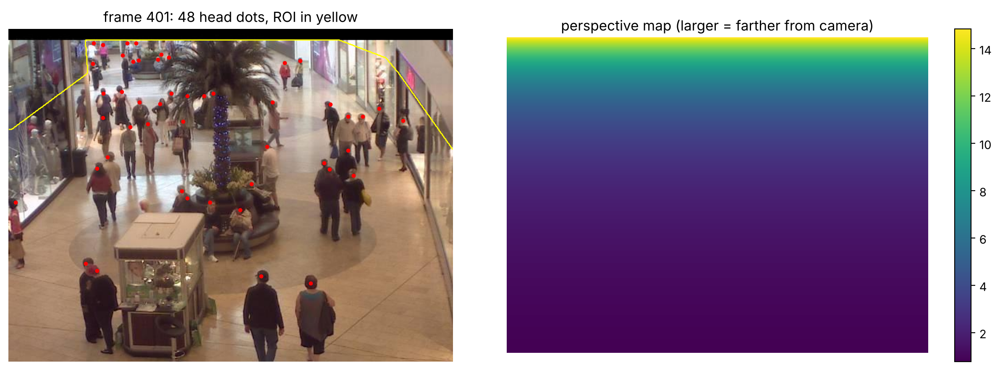

pmap at top / middle / bottom rows: 14.84264 2.0440447 0.772927


In [5]:
def read_frame(i):
    im = cv2.imread(ds['frames'][i], cv2.IMREAD_COLOR)
    assert im is not None, ds['frames'][i]
    return im

i_show = int(TRAIN_FRAMES[len(TRAIN_FRAMES) // 2])
im = read_frame(i_show)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
ax[0].contour(ds['roi'], levels=[0.5], colors='yellow', linewidths=1)
d = ds['dots'][i_show]
ax[0].plot(d[:, 0], d[:, 1], 'r.', ms=5)
ax[0].set_title(f'frame {i_show + 1}: {len(d)} head dots, ROI in yellow'); ax[0].axis('off')
pm = ax[1].imshow(ds['pmap'], cmap='viridis'); plt.colorbar(pm, ax=ax[1])
ax[1].set_title('perspective map (larger = farther from camera)'); ax[1].axis('off')
plt.tight_layout(); plt.show()
print('pmap at top / middle / bottom rows:', ds['pmap'][0, W_IMG // 2], ds['pmap'][H_IMG // 2, W_IMG // 2], ds['pmap'][-1, W_IMG // 2])

## 1.3 Ground-truth density map (Eq. 1)
$$F^0(p) = \sum_{\mu \in A} \mathcal{N}(p;\, \mu,\, \sigma^2 \mathbf{1}_{2\times 2}), \qquad \sigma = 2.5\ \text{px}$$
Each head dot $\mu$ becomes a small Gaussian whose total mass is 1. Summing the map over any region gives the number of people in that region.

frame 401: official count = 48, sum of GT density in ROI = 47.89
max |sum(density) - count| over 16 frames: 0.16  (small gaps = heads on the ROI border)


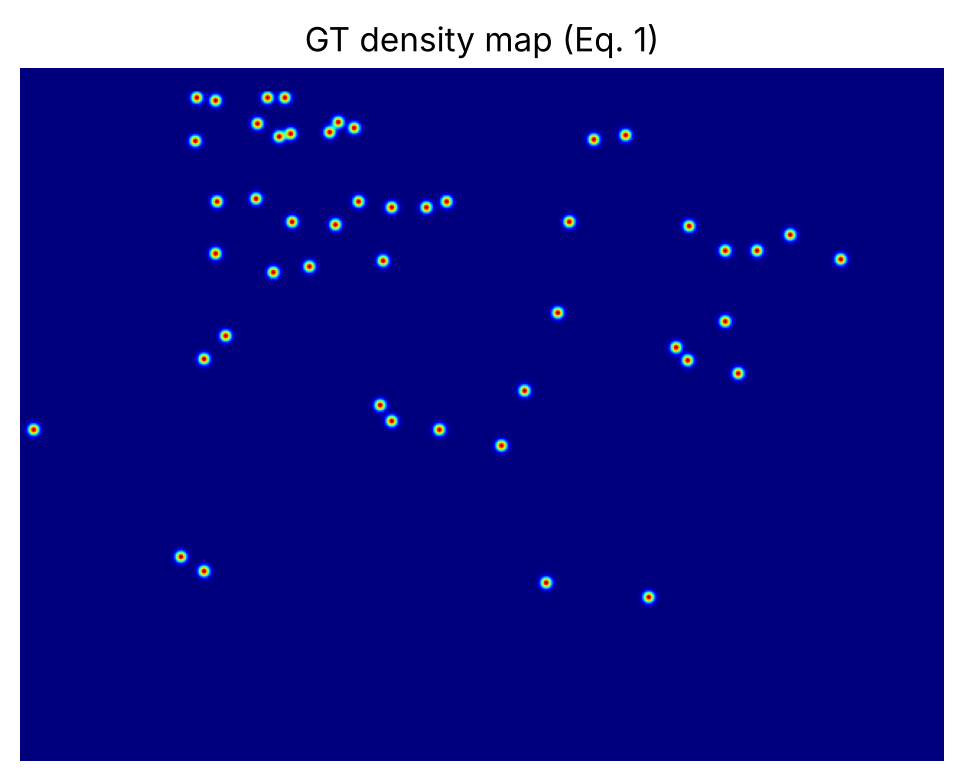

In [6]:
def gt_density(dots, shape=(H_IMG, W_IMG), sigma=SIGMA_GT, roi=None):
    D = np.zeros(shape, np.float32)
    if len(dots):
        xi = np.round(dots[:, 0]).astype(int); yi = np.round(dots[:, 1]).astype(int)
        ok = (xi >= 0) & (xi < shape[1]) & (yi >= 0) & (yi < shape[0])
        np.add.at(D, (yi[ok], xi[ok]), 1.0)
    D = ndi.gaussian_filter(D, sigma, mode='constant', truncate=4.0)
    return D * roi if roi is not None else D

F0 = gt_density(ds['dots'][i_show], roi=ds['roi'])
print(f'frame {i_show + 1}: official count = {ds["counts"][i_show]:.0f}, sum of GT density in ROI = {F0.sum():.2f}')
errs = [abs(gt_density(ds['dots'][i], roi=ds['roi']).sum() - ds['counts'][i]) for i in TRAIN_FRAMES[::50]]
print(f'max |sum(density) - count| over {len(errs)} frames: {max(errs):.2f}  (small gaps = heads on the ROI border)')
plt.figure(figsize=(6, 4.5)); plt.imshow(F0, cmap='jet'); plt.title('GT density map (Eq. 1)'); plt.axis('off'); plt.show()

## 1.4 Patch labels (Eq. 3) and the soft location histogram (Fig. 4)
For a patch centred at $O$, its label is the set of displacement vectors to every head within radius $R$:
$$l = \{\, \overrightarrow{OP_j} \;:\; P_j \in A,\ |\overrightarrow{OP_j}| < R \,\}$$
- The **label size** $K = |l|$ is the number of nearby heads. The lower split layer uses it (Eq. 6).
- The **soft histogram** $H_o$ is a $B\times B$ grid over $[-R, R]^2$. Each head adds a Gaussian bump to it. The upper split layer uses it to group patches whose heads sit in similar places (Eq. 5).

We store labels as a padded array `Dpad[n, K_MAX, 2]`, filled with NaN where there is no head.

**Choosing R matters a lot.** The paper doesn't give R. Each leaf predicts by **majority vote** over label sizes, so if most training patches have $K = 0$, real heads get out-voted and the counts come out too low.
With R = 12 px, 96% of Mall patches have $K = 0$. We measured this on validation frames 701–740 (Mall, trained on frames 1–700, 32 trees, stride 3):

| R (px) | patches with K = 0 | predicted mean count (true 39.65) | MAE | MSE | MDE |
|---|---|---|---|---|---|
| 12 | 96% | 31.0 | 8.68 | 88.7 | 0.214 |
| 18 | 91% | 44.9 | 5.33 | 40.8 | 0.140 |
| 24 | 86% | 42.1 | 3.45 | 19.2 | 0.091 |
| 32 | 78% | 38.1 | **2.76** | **11.0** | **0.069** |
| 40 | 71% | 35.6 | 4.14 | 24.3 | 0.102 |

Too small an R and the empty patches out-vote the heads. Too large and each leaf has to predict many far-away heads, which it does poorly.

For comparison, the paper reports 2.50 / 10.0 / 0.080 on the full Mall test set. A larger R also fits the paper's own figures, whose example labels contain 2–3 heads.
R = 32 is our default. Re-tune it for UCSD, where people are much smaller.

patch centred at (125,22): K = 3 heads within R=32.0
displacements:
[[-2.878 -1.697]
 [10.314  0.333]
 [-3.893 27.733]]


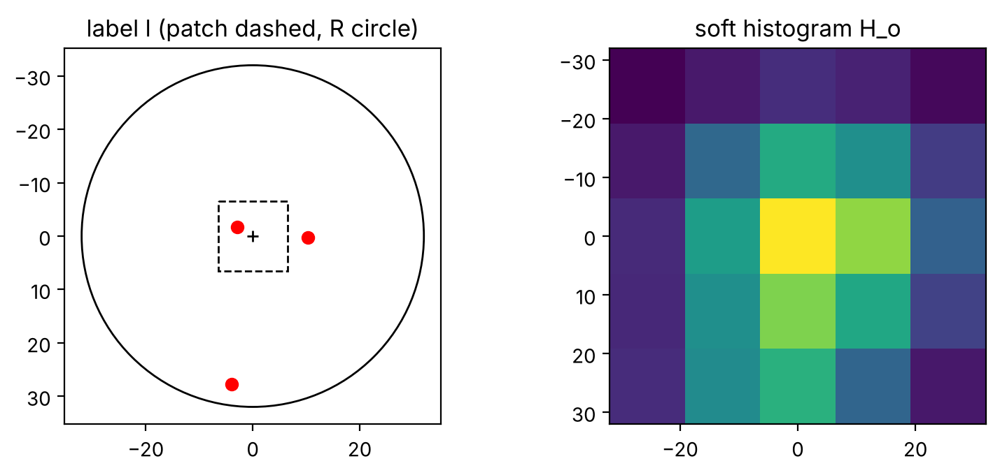

In [7]:
_edges = np.linspace(-R_LABEL, R_LABEL, HIST_BINS + 1)
_cent = (_edges[:-1] + _edges[1:]) / 2
HIST_CX, HIST_CY = np.meshgrid(_cent, _cent)               # bin centres, B x B
HIST_SIGMA = _edges[1] - _edges[0]                          # [ours] kernel width = one bin


def make_labels(centers, dots, R=R_LABEL, k_max=K_MAX):
    """centers: (N,2) int (x,y). Returns Dpad (N,k_max,2) float32 (NaN-padded), K (N,) int16."""
    N = len(centers)
    Dpad = np.full((N, k_max, 2), np.nan, np.float32)
    if len(dots) == 0:
        return Dpad, np.zeros(N, np.int16)
    diff = dots[None, :, :] - centers[:, None, :].astype(np.float32)    # N x M x 2
    near = (diff ** 2).sum(-1) < R * R
    K = near.sum(1)
    if K.max() > k_max:
        raise ValueError(f'label size {K.max()} > K_MAX={k_max}; increase K_MAX')
    rows, cols = np.nonzero(near)
    slot = np.zeros_like(rows)
    if len(rows):
        starts = np.r_[0, np.cumsum(K)[:-1]]
        slot = np.arange(len(rows)) - np.repeat(starts, K)
    Dpad[rows, slot] = diff[rows, cols]
    return Dpad, K.astype(np.int16)


def soft_histograms(Dpad):
    """Soft B x B histogram of each label's head positions -> (N, B*B) float32."""
    dx = Dpad[:, :, 0][:, :, None] - HIST_CX.ravel()[None, None, :]
    dy = Dpad[:, :, 1][:, :, None] - HIST_CY.ravel()[None, None, :]
    w = np.exp(-(dx ** 2 + dy ** 2) / (2 * HIST_SIGMA ** 2))
    return np.nan_to_num(w).sum(1).astype(np.float32)          # NaN slots contribute 0


# quick look at one label
cx, cy = ds['dots'][i_show][0].round().astype(int)
Dp, Kp = make_labels(np.array([[cx + 3, cy + 2]]), ds['dots'][i_show])
Hp = soft_histograms(Dp).reshape(HIST_BINS, HIST_BINS)
print(f'patch centred at ({cx + 3},{cy + 2}): K = {Kp[0]} heads within R={R_LABEL}\n'
      f'displacements:\n{Dp[0, :Kp[0]]}')
fig, ax = plt.subplots(1, 2, figsize=(8, 3.5))
ax[0].scatter(Dp[0, :Kp[0], 0], Dp[0, :Kp[0], 1], c='r'); ax[0].add_patch(plt.Circle((0, 0), R_LABEL, fill=False))
ax[0].add_patch(plt.Rectangle((-HALF - .5, -HALF - .5), PATCH, PATCH, fill=False, ls='--'))
ax[0].plot(0, 0, 'k+'); ax[0].set_aspect('equal'); ax[0].invert_yaxis(); ax[0].set_title('label l (patch dashed, R circle)')
ax[1].imshow(Hp, extent=[-R_LABEL, R_LABEL, R_LABEL, -R_LABEL]); ax[1].set_title('soft histogram H_o')
plt.tight_layout(); plt.show()

## 1.5 Metrics (Sec. 5.1)
- $\text{MAE} = \mathbb{E}\,|\kappa - \hat\kappa|$
- $\text{MSE} = \mathbb{E}\,(\kappa - \hat\kappa)^2$, **with no square root**. That is what the paper reports; RMSE is printed as well.
- $\text{MDE} = \mathbb{E}\,\big(|\kappa - \hat\kappa| / \kappa\big)$

Here $\kappa$ is the true count and $\hat\kappa$ is the sum of the estimated density inside the ROI.

In [8]:
def count_metrics(gt, pred):
    gt, pred = np.asarray(gt, float), np.asarray(pred, float)
    e = pred - gt
    return dict(MAE=np.abs(e).mean(), MSE=(e ** 2).mean(), RMSE=np.sqrt((e ** 2).mean()),
                MDE=(np.abs(e) / np.maximum(gt, 1e-9)).mean())

print(count_metrics([10, 20, 30], [11, 18, 30]))

{'MAE': np.float64(1.0), 'MSE': np.float64(1.6666666666666667), 'RMSE': np.float64(1.2909944487358056), 'MDE': np.float64(0.06666666666666667)}


# Phase 2: The 15 feature channels (Sec. 5)
The paper lists these channels:
1. the raw image (gray)
2. the background-subtraction result (MOG2 foreground mask)
3. the temporal derivative $|I_t - I_{t-1}|$
4. at each scale $\sigma \in \{0.8, 1.6, 3.2\}$: Gaussian gradient magnitude, Laplacian of Gaussian, and the two eigenvalues of the structure tensor

That gives $3 + 3 \times 4 = 15$ channels.

**Structure tensor [ours].** The paper doesn't give the two scales. We take derivatives at scale $\sigma$ and average their products over a Gaussian window of scale $2\sigma$:
$$J = G_{2\sigma} * \begin{pmatrix} I_x^2 & I_xI_y \\ I_xI_y & I_y^2 \end{pmatrix}, \qquad \lambda_{1,2} = \tfrac{J_{xx}+J_{yy}}{2} \pm \sqrt{\big(\tfrac{J_{xx}-J_{yy}}{2}\big)^2 + J_{xy}^2}$$

## 2.1 Perspective weighting
The paper multiplies *all* feature values by the square of the camera perspective map. Squaring turns a linear scale factor (person height) into an area factor.
Mall's `pMapN` changes by about 19× from the top of the image to the bottom, while a person's height changes by only about 4–5×. So `pMapN` already behaves like an **area** weight, and `PERSP_POWER = 1` is the equivalent of the paper's square.
Set `PERSP_POWER = 2` to follow the paper literally, and compare the two on the validation frames.

**Causality.** MOG2 and the temporal derivative must see the frames in order, starting from frame 1. `stream_channels` always starts at frame 1, even if you only need later frames.

In [9]:
CHANNEL_NAMES = ['gray', 'bgsub', 'dI/dt'] + [f'{n}@{s}' for s in SCALES for n in ('gradmag', 'LoG', 'st_l1', 'st_l2')]
N_CH = len(CHANNEL_NAMES)
PERSP_W = (ds['pmap'] ** PERSP_POWER).astype(np.float32)


class ChannelExtractor:
    """Stateful: call once per frame, in temporal order, starting from frame 1."""
    def __init__(self, weight=PERSP_W, history=BG_HISTORY):
        self.bg = cv2.createBackgroundSubtractorMOG2(history=history, varThreshold=16, detectShadows=False)
        self.prev = None
        self.weight = weight

    def __call__(self, bgr):
        gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY).astype(np.float32) / 255.0
        fg = self.bg.apply(bgr)
        fg = (cv2.medianBlur(fg, 3) > 127).astype(np.float32)
        dt = np.zeros_like(gray) if self.prev is None else np.abs(gray - self.prev)
        self.prev = gray
        ch = [gray, fg, dt]
        for s in SCALES:
            ch.append(ndi.gaussian_gradient_magnitude(gray, s))
            ch.append(ndi.gaussian_laplace(gray, s))
            ix = ndi.gaussian_filter(gray, s, order=(0, 1))
            iy = ndi.gaussian_filter(gray, s, order=(1, 0))
            jxx = ndi.gaussian_filter(ix * ix, 2 * s)
            jyy = ndi.gaussian_filter(iy * iy, 2 * s)
            jxy = ndi.gaussian_filter(ix * iy, 2 * s)
            tr, disc = (jxx + jyy) / 2, np.sqrt(((jxx - jyy) / 2) ** 2 + jxy ** 2)
            ch += [tr + disc, tr - disc]
        return np.stack(ch, 0).astype(np.float32) * self.weight[None]


def stream_channels(last_frame):
    """Yield (frame_index, channels[15,H,W]) for frames 0..last_frame, in order."""
    ext = ChannelExtractor()
    for i in range(last_frame + 1):
        yield i, ext(read_frame(i))

## 2.2 Look at the channels
We run the extractor from frame 1 up to the display frame, so MOG2 has had time to warm up.

401 frames in 82.2s (205 ms/frame)


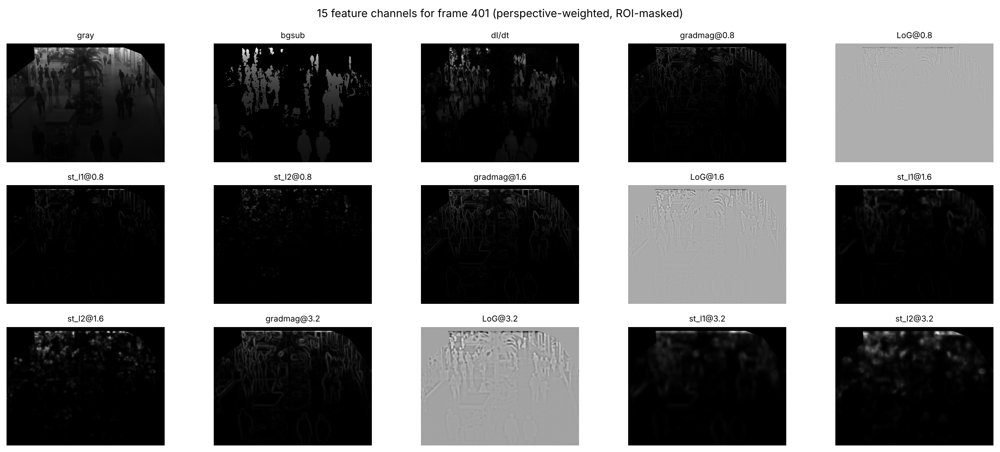

In [10]:
t0 = time.time()
for i, C_show in stream_channels(i_show):
    pass
print(f'{i_show + 1} frames in {time.time() - t0:.1f}s ({(time.time() - t0) / (i_show + 1) * 1000:.0f} ms/frame)')
fig, axs = plt.subplots(3, 5, figsize=(16, 7))
for k, a in enumerate(axs.ravel()):
    a.imshow(C_show[k] * ds['roi'], cmap='gray'); a.set_title(CHANNEL_NAMES[k], fontsize=9); a.axis('off')
plt.suptitle(f'15 feature channels for frame {i_show + 1} (perspective-weighted, ROI-masked)'); plt.tight_layout(); plt.show()

# Phase 3: Building the COUNT Forest
## 3.1 Patch features and the patch pool
A patch feature $v \in \mathbb{R}^{13\cdot13\cdot15}$ concatenates every channel's response at every pixel of the patch.
We lay it out channel-major, so element $f = c\cdot169 + (dy+6)\cdot13 + (dx+6)$.
This means Phase 4 can read any feature straight from the channel stack without building patch vectors.

**Sampling.** Patch centres are drawn uniformly at random inside the ROI, at least 6 px from the image border.
Uniform sampling matters because the leaves predict by **majority vote**, so the training patches must have the same mix of empty and crowded patches as the dense test-time grid.

Features are stored as float16 to halve memory. At test time, cast to float16 too, so the threshold comparisons behave exactly as they did in training.

In [11]:
OFF_Y, OFF_X = [o.ravel() for o in np.mgrid[-HALF:HALF + 1, -HALF:HALF + 1]]
N_FEAT = N_CH * PATCH * PATCH
VALID_CENTER = ds['roi'].copy()
VALID_CENTER[:HALF, :] = VALID_CENTER[-HALF:, :] = VALID_CENTER[:, :HALF] = VALID_CENTER[:, -HALF:] = False
_vy, _vx = np.nonzero(VALID_CENTER)
VALID_XY = np.stack([_vx, _vy], 1).astype(np.int32)


def patch_features(C, centers):
    """C: (15,H,W) channels; centers: (N,2) int (x,y) -> (N, 15*13*13) channel-major."""
    ys = centers[:, 1:2] + OFF_Y[None]
    xs = centers[:, 0:1] + OFF_X[None]
    return C[:, ys, xs].transpose(1, 0, 2).reshape(len(centers), -1)


def build_patch_pools(groups, per_frame, seed):
    """groups: {'train': frame_ids, 'val': frame_ids, ...}. One pass over the video, in order;
    for every frame in a group, sample `per_frame` patch centres and store features + labels."""
    rng = np.random.default_rng(seed)
    owner = {int(i): g for g, ids in groups.items() for i in ids}
    pools, ptr = {}, {}
    for g, ids in groups.items():
        n = len(ids) * per_frame
        pools[g] = dict(V=np.empty((n, N_FEAT), np.float16), Dpad=np.empty((n, K_MAX, 2), np.float32),
                        K=np.empty(n, np.int16), H=np.empty((n, HIST_BINS * HIST_BINS), np.float32),
                        meta=np.empty((n, 3), np.int32))           # meta = frame, x, y
        ptr[g] = 0
    t0 = time.time()
    for i, C in stream_channels(max(owner)):
        g = owner.get(i)
        if g is None:
            continue
        ctr = VALID_XY[rng.choice(len(VALID_XY), per_frame, replace=False)]
        P, sl = pools[g], slice(ptr[g], ptr[g] + per_frame)
        P['V'][sl] = patch_features(C, ctr)
        P['Dpad'][sl], P['K'][sl] = make_labels(ctr, ds['dots'][i])
        P['H'][sl] = soft_histograms(P['Dpad'][sl])
        P['meta'][sl] = np.c_[np.full(per_frame, i), ctr]
        ptr[g] += per_frame
    for g, P in pools.items():
        print(f'[{g}] {ptr[g]} patches from {len(groups[g])} frames, V = {P["V"].nbytes / 1e9:.2f} GB, '
              f'max label size {P["K"].max()}')
    print(f'pass over {max(owner) + 1} frames took {time.time() - t0:.0f}s')
    return pools


def save_pool(pool, path):
    os.makedirs(path, exist_ok=True)
    for k, v in pool.items():
        np.save(os.path.join(path, f'{k}.npy'), v)


def load_pool(path, mmap=True):
    return {k: np.load(os.path.join(path, f'{k}.npy'), mmap_mode='r' if (mmap and k == 'V') else None)
            for k in ('V', 'Dpad', 'K', 'H', 'meta')}


POOL_TAG = f'{DATASET}_{"tune" if TUNING else "final"}_{"dev" if FAST_DEV else "full"}_p{PATCHES_PER_FRAME}_s{FRAME_STEP}_R{R_LABEL:g}_pp{PERSP_POWER:g}'
TRAIN_POOL_DIR = os.path.join(CACHE_DIR, 'pool_train_' + POOL_TAG)
VAL_POOL_DIR = os.path.join(CACHE_DIR, 'pool_val_' + POOL_TAG)

_need = {}
if not os.path.exists(os.path.join(TRAIN_POOL_DIR, 'meta.npy')):
    _need['train'] = TRAIN_FRAMES[::FRAME_STEP]
if TUNING and not os.path.exists(os.path.join(VAL_POOL_DIR, 'meta.npy')):
    _need['val'] = VAL_FRAMES[::FRAME_STEP]
if _need:
    _pools = build_patch_pools(_need, PATCHES_PER_FRAME, SEED)
    for g, P in _pools.items():
        save_pool(P, TRAIN_POOL_DIR if g == 'train' else VAL_POOL_DIR)
    del _pools

pool = load_pool(TRAIN_POOL_DIR)
kk = np.bincount(pool['K'])
print('training label-size distribution (K: share of patches):',
      {k: f'{c / kk.sum():.3f}' for k, c in enumerate(kk) if c})

training label-size distribution (K: share of patches): {0: '0.777', 1: '0.143', 2: '0.052', 3: '0.017', 4: '0.006', 5: '0.002', 6: '0.001', 7: '0.000', 8: '0.000', 9: '0.000'}


## 3.2 The two split criteria, vectorised
At each node we draw $J$ random tests $(f_j, t_j)$, where $f_j$ is one random element of $v$ (Eq. 4). A sample goes left if $v_{f_j} < t_j$.

**Upper layer (Eq. 5): group by where the heads are.**
$$\sum_{o\in S_L}\|H_o-\bar H_L\|_F^2+\sum_{o\in S_R}\|H_o-\bar H_R\|_F^2 \;=\; \underbrace{\sum_o \|H_o\|^2}_{\text{same for every split}} - \frac{\|S_L\|^2}{n_L} - \frac{\|S_R\|^2}{n_R}$$
Here $S_L = \sum_{o \in S_L} H_o$ (and likewise $S_R$). The first term is the same for every split, so minimising Eq. 5 means **maximising** $\|S_L\|^2/n_L + \|S_R\|^2/n_R$.
With an indicator matrix $M \in \{0,1\}^{n\times J}$ (1 where a sample goes left), all $J$ candidates come out of one matrix product: $S_L = M^\top H$, and $S_R = S_{\text{tot}} - S_L$.

**Lower layer (Eq. 6): group by how many heads there are.**
$$\frac{|S_L|}{|S|}\,\mathcal{H}(S_L) + \frac{|S_R|}{|S|}\,\mathcal{H}(S_R)$$
Here $\mathcal{H}$ is the Shannon entropy of the label-size distribution. Class counts come from the same trick: $C_L = M^\top Y$, where $Y$ is the one-hot encoding of $K$.

In [12]:
def _entropy_rows(C, n):
    P = C / np.maximum(n, 1)[:, None]
    with np.errstate(divide='ignore', invalid='ignore'):
        return -(np.where(P > 0, P * np.log2(P), 0.0)).sum(1)


def best_split(V, idx, layer, Hn, Yn, rng, J=J_SPLITS, min_child=MIN_CHILD, allowed=None):
    """Returns (feature, threshold, go_left mask) or None. Hn/Yn are H[idx]/Y[idx]. allowed: optional array of usable feature ids."""
    n = len(idx)
    feats = rng.integers(0, V.shape[1], size=J) if allowed is None else allowed[rng.integers(0, len(allowed), size=J)]
    X = np.asarray(V[np.ix_(idx, feats)], dtype=np.float32)           # n x J
    thr = X[rng.integers(0, n, size=J), np.arange(J)]
    M = X < thr[None, :]
    nL = M.sum(0).astype(np.float64); nR = n - nL
    valid = (nL >= min_child) & (nR >= min_child)
    if not valid.any():
        return None
    Mf = M.astype(np.float32)
    if layer == 'upper':
        SL = Mf.T @ Hn; SR = Hn.sum(0)[None, :] - SL
        score = (SL.astype(np.float64) ** 2).sum(1) / np.maximum(nL, 1) + (SR.astype(np.float64) ** 2).sum(1) / np.maximum(nR, 1)
    else:
        CL = (Mf.T @ Yn).astype(np.float64); CR = Yn.sum(0)[None, :] - CL
        score = -(nL * _entropy_rows(CL, nL) + nR * _entropy_rows(CR, nR))
    score[~valid] = -np.inf
    j = int(np.argmax(score))
    return int(feats[j]), float(thr[j]), M[:, j]


# Check: the vectorised Eq. 5 should match a brute-force computation on a toy node
_rng = np.random.default_rng(1)
_Vt = _rng.normal(size=(60, 10)).astype(np.float16)
_Ht = _rng.random((60, 4)).astype(np.float32)
f, t, gl = best_split(_Vt, np.arange(60), 'upper', _Ht, None, np.random.default_rng(3), J=50)
def _eq5(mask):
    return sum(((_Ht[m] - _Ht[m].mean(0)) ** 2).sum() for m in (mask, ~mask))
_r = np.random.default_rng(3); _feats = _r.integers(0, 10, 50)
_X = _Vt[:, _feats].astype(np.float32); _thr = _X[_r.integers(0, 60, 50), np.arange(50)]
_costs = [_eq5(_X[:, j] < _thr[j]) if min((_X[:, j] < _thr[j]).sum(), (_X[:, j] >= _thr[j]).sum()) >= MIN_CHILD else np.inf for j in range(50)]
print(f'vectorised pick: Eq.5 cost {_eq5(gl):.4f} | brute-force minimum {min(_costs):.4f}')
assert np.isclose(_eq5(gl), min(_costs), rtol=1e-4), 'vectorised Eq. 5 disagrees with brute force'

vectorised pick: Eq.5 cost 20.3512 | brute-force minimum 20.3512


## 3.3 Growing one tree, and the leaf prediction model (Sec. 3.2, Fig. 5)
Nodes at depth below `UPPER_DEPTH` (with at least `N_MIN_UPPER` samples) use Eq. 5. Deeper nodes use Eq. 6, down to `MAX_DEPTH` or until fewer than `N_MIN` samples remain.
A node also becomes a leaf when there's nothing left to separate: in the upper layer the labels all have the same histogram, and in the lower layer they all have the same size.

**Leaf prediction.**
1. Group the leaf's labels by size $K$ and keep the largest group $G$.
2. Pool all head positions of the labels in $G$ and run **K-means with $K$ clusters**.
3. The leaf stores only the $K$ centroids, as one predicted label.

The tree is stored as flat arrays, which makes prediction vectorised and the model tiny.

In [13]:
def kmeans_small(P, k, rng, iters=30):
    """Lloyd's K-means with k-means++ initialisation for small 2-D point sets."""
    cent = [P[rng.integers(len(P))]]
    for _ in range(1, k):
        d2 = np.min(((P[:, None, :] - np.array(cent)[None]) ** 2).sum(-1), 1)
        cent.append(P[rng.choice(len(P), p=d2 / d2.sum())] if d2.sum() > 0 else P[rng.integers(len(P))])
    cent = np.array(cent, np.float32)
    for _ in range(iters):
        lab = ((P[:, None, :] - cent[None]) ** 2).sum(-1).argmin(1)
        new = np.array([P[lab == c].mean(0) if np.any(lab == c) else cent[c] for c in range(k)], np.float32)
        if np.allclose(new, cent):
            break
        cent = new
    return cent


def grow_tree(V, H, Y, K, Dpad, idx_root, rng, max_depth=MAX_DEPTH, upper_depth=UPPER_DEPTH,
              n_min=N_MIN, n_min_upper=N_MIN_UPPER, allowed=None):
    feat, thr, left, right, leaf_k, leaf_off, pts = [], [], [], [], [], [], []
    def new_node():
        for a in (feat, left, right, leaf_k, leaf_off): a.append(-1)
        thr.append(0.0); return len(feat) - 1
    stack = [(new_node(), np.sort(idx_root), 0)]
    while stack:
        nid, idx, depth = stack.pop()
        n = len(idx)
        Hn = H[idx]; Ks = K[idx]
        layer = None
        if depth < upper_depth and n >= n_min_upper and Hn.std(0).max() > 1e-6:
            layer = 'upper'
        elif depth < max_depth and n >= n_min and Ks.min() != Ks.max():
            layer = 'lower'
        sp = best_split(V, idx, layer, Hn, Y[idx], rng, allowed=allowed) if layer else None
        if sp is None:                                            # ---- leaf ----
            cnt = np.bincount(Ks)
            k_star = int(np.argmax(cnt))                          # majority label size (ties -> smaller K)
            leaf_k[nid], leaf_off[nid] = k_star, sum(len(p) for p in pts)
            if k_star > 0:
                P = Dpad[idx[Ks == k_star], :k_star].reshape(-1, 2)
                pts.append(kmeans_small(P, k_star, rng))
            continue
        f, t, gl = sp
        l, r = new_node(), new_node()
        feat[nid], thr[nid], left[nid], right[nid] = f, t, l, r
        stack += [(l, idx[gl], depth + 1), (r, idx[~gl], depth + 1)]
    return dict(feature=np.array(feat, np.int32), threshold=np.array(thr, np.float32),
                left=np.array(left, np.int32), right=np.array(right, np.int32),
                leaf_k=np.array(leaf_k, np.int16), leaf_off=np.array(leaf_off, np.int32),
                points=np.concatenate(pts).astype(np.float32) if pts else np.zeros((0, 2), np.float32))


def tree_apply(tree, X):
    """Route each row of X (n x N_FEAT) to a leaf; returns leaf node ids."""
    node = np.zeros(len(X), np.int32)
    active = np.arange(len(X))
    while len(active):
        nd = node[active]
        internal = tree['left'][nd] >= 0
        active, nd = active[internal], nd[internal]
        if not len(active):
            break
        go = np.asarray(X[active, tree['feature'][nd]], np.float32) < tree['threshold'][nd]
        node[active] = np.where(go, tree['left'][nd], tree['right'][nd])
    return node


def leaf_label(tree, leaf):
    """Predicted displacement vectors (K x 2) stored at a leaf."""
    k, o = tree['leaf_k'][leaf], tree['leaf_off'][leaf]
    return tree['points'][o:o + k]

## 3.4 Training the forest
Each tree gets its own random subset of the patch pool ([ours] bagging) and its own random seed. Trees are trained in parallel.
`train_forest` also takes a `subset` of patch indices. Phase 5's crowdedness prior uses this to train separate crowded and non-crowded forests on the same pool.

In [14]:
def _train_one(tree_id, pool_dir, subset, samples_per_tree, seed, upper_depth=UPPER_DEPTH, allowed=None):
    P = load_pool(pool_dir)
    rng = np.random.default_rng(seed + 1000 * tree_id)
    K = np.asarray(P['K']).astype(np.int64)
    Y = np.eye(K_MAX + 1, dtype=np.float32)[K]
    base = np.arange(len(K)) if subset is None else np.asarray(subset)
    idx = rng.choice(base, size=min(samples_per_tree, len(base)), replace=False)
    t0 = time.time()
    tree = grow_tree(P['V'], P['H'], Y, K, P['Dpad'], idx, rng, upper_depth=upper_depth, allowed=allowed)
    tree['train_time'] = time.time() - t0
    return tree


def train_forest(pool_dir, n_trees=N_TREES, subset=None, samples_per_tree=SAMPLES_PER_TREE, seed=SEED, n_jobs=N_JOBS,
                 upper_depth=UPPER_DEPTH, allowed=None):
    t0 = time.time()
    trees = Parallel(n_jobs=n_jobs, verbose=0)(
        delayed(_train_one)(t, pool_dir, subset, samples_per_tree, seed, upper_depth, allowed) for t in range(n_trees))
    print(f'trained {n_trees} trees in {time.time() - t0:.0f}s')
    return trees


def forest_stats(trees):
    n_leaves = [int((t['left'] < 0).sum()) for t in trees]
    size_mb = sum(sum(v.nbytes for v in t.values() if isinstance(v, np.ndarray)) for t in trees) / 1e6
    leaf_ks = np.concatenate([t['leaf_k'][t['left'] < 0] for t in trees])
    return dict(trees=len(trees), mean_leaves=np.mean(n_leaves), size_MB=round(size_mb, 2),
                share_empty_leaves=round(float((leaf_ks == 0).mean()), 3), max_leaf_K=int(leaf_ks.max()))


FOREST_PATH = os.path.join(CACHE_DIR, f'forest_{POOL_TAG}_T{N_TREES}.joblib')
if os.path.exists(FOREST_PATH):
    forest = joblib.load(FOREST_PATH)
    print('loaded cached forest:', end=' ')
else:
    forest = train_forest(TRAIN_POOL_DIR)
    joblib.dump(forest, FOREST_PATH)
print(forest_stats(forest), '->', FOREST_PATH)

loaded cached forest: {'trees': 32, 'mean_leaves': np.float64(1107.65625), 'size_MB': 1.73, 'share_empty_leaves': 0.616, 'max_leaf_K': 8} -> cache/forest_mall_final_full_p300_s1_R32_pp1_T32.joblib


## 3.5 Patch-level sanity check
For each validation patch, each tree predicts a label size $\hat K$, the number of heads within $R$. We average $\hat K$ over the trees.
- Leaves predict the **most common** K (majority vote), so the average $\hat K$ is expected to sit *below* the true mean K. That's normal. What matters is the frame-level count in 3.6.
- This check only confirms that the forest learned something: its MAE should beat a constant predictor, and $\hat K$ should rise with the true K.

In [15]:
if TUNING:
    vpool = load_pool(VAL_POOL_DIR, mmap=False)
    Xv = vpool['V']; Kv = vpool['K'].astype(float)
    t0 = time.time()
    Khat_trees = np.stack([t['leaf_k'][tree_apply(t, Xv)] for t in forest]).astype(float)
    dt_pred = time.time() - t0
    Khat = Khat_trees.mean(0)
    base = np.full_like(Kv, np.asarray(pool['K']).mean())
    print(f'{len(Kv)} validation patches, prediction {dt_pred / len(Kv) * 1e6:.1f} us/patch for {len(forest)} trees')
    print(f'patch-level MAE of K  forest: {np.abs(Khat - Kv).mean():.3f}   constant baseline: {np.abs(base - Kv).mean():.3f}')
    print(f'mean K  true: {Kv.mean():.3f}   forest: {Khat.mean():.3f}   (lower is expected: leaves vote for the most common K)')
    print(f'single-tree exact-K accuracy: {(Khat_trees == Kv[None]).mean():.3f}')
    bins = np.arange(int(Kv.max()) + 1)
    mean_pred = [Khat[Kv == b].mean() if np.any(Kv == b) else np.nan for b in bins]
    plt.figure(figsize=(5.5, 4))
    plt.plot(bins, mean_pred, 'o-', label='forest (mean over patches)'); plt.plot(bins, bins, 'k--', label='ideal')
    plt.xlabel('true label size K'); plt.ylabel('predicted K'); plt.legend(); plt.title('validation patches'); plt.show()

    # Where do the predicted heads land?  Compare one tree's leaf label with the truth for a few crowded patches
    t = forest[0]; leaves = tree_apply(t, Xv)
    ex = np.nonzero(Kv >= 2)[0][:4]
    fig, axs = plt.subplots(1, len(ex), figsize=(3.2 * len(ex), 3.2))
    for a, e in zip(np.atleast_1d(axs), ex):
        tl = vpool['Dpad'][e, :int(Kv[e])]; pl = leaf_label(t, leaves[e])
        a.scatter(tl[:, 0], tl[:, 1], c='r', label='true'); a.scatter(pl[:, 0], pl[:, 1], marker='x', c='b', label='tree 0')
        a.add_patch(plt.Circle((0, 0), R_LABEL, fill=False)); a.set_xlim(-R_LABEL - 1, R_LABEL + 1); a.set_ylim(R_LABEL + 1, -R_LABEL - 1)
        a.set_aspect('equal'); a.set_title(f'K={int(Kv[e])}, predicted {len(pl)}')
    np.atleast_1d(axs)[0].legend(fontsize=8); plt.tight_layout(); plt.show()

## 3.6 Density estimation: Eq. 7–9, fast version
This section turns the forest into a density map.
- **Eq. 7.** Every predicted head $\mu$ in a patch's leaf label adds a Gaussian $\mathcal{N}(x;\mu,\sigma^2)$ to that patch's 13×13 window. In window coordinates, $x-\mu$ = window offset − predicted displacement.
- **Eq. 8.** Average the patch density over the trees that predict the patch.
- **Eq. 9.** At each pixel, average over all patches whose window covers that pixel.
- **Count.** Sum the density map inside the ROI.

**Why a second implementation.** The straightforward version (`density_map_reference`) builds the 2535-value vector of every patch, about 150 MB per frame, although a tree reads only one value per node. A feature is one pixel of one channel at a fixed offset from the patch centre. `density_fast` therefore reads those pixels straight from the channel stack and writes the Gaussians as a product of two 1-D Gaussians. The leaves and the density are identical to the reference (checked on the first frame of every evaluation in section 5, tolerance 1e-6). It is about 6× faster, which makes the 1200-frame test run practical.

In [16]:
def grid_centers(stride):
    gy, gx = np.mgrid[HALF:H_IMG - HALF:stride, HALF:W_IMG - HALF:stride]
    m = VALID_CENTER[gy, gx]
    return np.stack([gx[m], gy[m]], 1).astype(np.int32)


def density_map_reference(C, trees, centers, sigma=SIGMA_GT):
    """Straightforward version of Eq. 7-9: build every patch vector, route it through the trees. Slow; kept as a reference."""
    X = patch_features(C, centers).astype(np.float16)           # same precision as training
    ox, oy = OFF_X.astype(np.float32), OFF_Y.astype(np.float32)
    vals = np.zeros((len(centers), PATCH * PATCH), np.float32)
    for t in trees:
        leaf = tree_apply(t, X)
        k = t['leaf_k'][leaf].astype(int)
        for j in range(1, int(k.max()) + 1):                     # j-th predicted head of each label
            sel = np.nonzero(k >= j)[0]
            mu = t['points'][t['leaf_off'][leaf[sel]] + j - 1]    # displacement from patch centre
            d2 = (ox[None] - mu[:, :1]) ** 2 + (oy[None] - mu[:, 1:]) ** 2
            vals[sel] += np.exp(-d2 / (2 * sigma ** 2)) / (2 * np.pi * sigma ** 2)   # Eq. 7
    vals /= len(trees)                                                            # Eq. 8
    flat = ((centers[:, 1:2] + OFF_Y[None]) * W_IMG + (centers[:, 0:1] + OFF_X[None])).ravel()
    S = np.bincount(flat, weights=vals.ravel(), minlength=H_IMG * W_IMG)
    N = np.bincount(flat, minlength=H_IMG * W_IMG)
    return (S / np.maximum(N, 1)).reshape(H_IMG, W_IMG).astype(np.float32)        # Eq. 9


HW = H_IMG * W_IMG


def prepare_tree(t):
    """Add arrays that let a tree read its split features straight from the channel stack (no patch matrix).
    Feature f = c*169 + (dy+6)*13 + (dx+6)  ->  flat offset c*H*W + dy*W + dx from the patch centre.
    Leaves point to themselves, so routing is a fixed number of array lookups."""
    f = t['feature'].astype(np.int64)
    internal = t['left'] >= 0
    c, k = np.divmod(np.where(internal, f, 0), PATCH * PATCH)
    off = c * HW + (k // PATCH - HALF) * W_IMG + (k % PATCH - HALF)
    me = np.arange(len(f), dtype=np.int32)
    t['off'] = np.where(internal, off, 0).astype(np.int32)
    t['L'] = np.where(internal, t['left'], me).astype(np.int32)
    t['R'] = np.where(internal, t['right'], me).astype(np.int32)
    t['depth'] = int(MAX_DEPTH)
    return t


def tree_apply_fast(t, C16, pos):
    """Same result as tree_apply(t, patch_features(C, centres).astype(float16)) but without building the patches."""
    node = np.zeros(len(pos), np.int32)
    for _ in range(t['depth']):
        go = C16[pos + t['off'][node]].astype(np.float32) < t['threshold'][node]
        node = np.where(go, t['L'][node], t['R'][node])
    return node


_OX, _OY = OFF_X[:PATCH].astype(np.float32), OFF_Y[::PATCH].astype(np.float32)      # window offsets -6..6


def make_grid(stride):
    ctr = grid_centers(stride)
    flat = ((ctr[:, 1:2] + OFF_Y[None]) * W_IMG + (ctr[:, 0:1] + OFF_X[None])).ravel()
    return dict(ctr=ctr, pos=(ctr[:, 1] * W_IMG + ctr[:, 0]).astype(np.int32), flat=flat,
                cover=np.maximum(np.bincount(flat, minlength=HW), 1).astype(np.float32),
                gy=(ctr[:, 1] - HALF) // stride, gx=(ctr[:, 0] - HALF) // stride)


def density_fast(C, grid, groups, sigma=SIGMA_GT):
    """groups: list of (trees, patch_index_array or None).  Every patch is predicted by the trees of its own
    group only (Eq. 7-8 over those trees); all patches are then averaged per pixel (Eq. 9)."""
    C16 = C.astype(np.float16).ravel()
    n = len(grid['pos'])
    vals = np.zeros((n, PATCH, PATCH), np.float32)
    for trees, sel in groups:
        sel = np.arange(n) if sel is None else sel
        if not len(sel):
            continue
        p, acc = grid['pos'][sel], np.zeros((len(sel), PATCH, PATCH), np.float32)
        for t in trees:
            leaf = tree_apply_fast(t, C16, p)
            k = t['leaf_k'][leaf].astype(int)
            for j in range(1, int(k.max()) + 1):                      # j-th predicted head of each label
                s = np.nonzero(k >= j)[0]
                mu = t['points'][t['leaf_off'][leaf[s]] + j - 1]       # displacement from the patch centre
                gx = np.exp(-(_OX[None] - mu[:, :1]) ** 2 / (2 * sigma ** 2))
                gy = np.exp(-(_OY[None] - mu[:, 1:]) ** 2 / (2 * sigma ** 2))
                acc[s] += gy[:, :, None] * gx[:, None, :] / (2 * np.pi * sigma ** 2)     # Eq. 7 (separable)
        vals[sel] = acc / len(trees)                                                       # Eq. 8
    S = np.bincount(grid['flat'], weights=vals.ravel(), minlength=HW)
    return (S / grid['cover']).reshape(H_IMG, W_IMG).astype(np.float32)                    # Eq. 9

# Phase 4: Robust density estimation (paper Sec. 4)
Two improvements on top of the plain COUNT Forest ("CF"). Both change *which trees predict a patch*, and neither changes how the trees are trained.

**4.1 Crowdedness prior.** Crowded and non-crowded patches look different, so the paper trains two forests, one on each kind of patch. A patch is crowded if the number $N_i$ of heads in its neighbourhood is in $[N/3,\,N]$, and non-crowded if $N_i\in[0,\,2N/3]$ (the ranges overlap). Here $N_i$ is the label size $K$ and $N$ is a constant. At test time, the patch picks its forest from the *previous frame's* estimated density: if the estimated number of heads within $R$ of the patch centre is above $N/2$, it uses the crowded forest, otherwise the non-crowded forest (Eq. 10–12). Only one forest is evaluated per patch, so the cost is unchanged. The first frame uses the plain forest.
- The paper takes $N=\max_i N_i$, which is 9 on Mall. Only 2.7% of patches have $K\geq 3$, so the crowded forest is trained on very few patches. Section 5.2 compares it with $N=6$.

**4.2 Forest permutation.** The forest is split into 4 sub-forests of 8 trees. The patch at grid position $(g_x,g_y)$ uses only sub-forest $(g_y \bmod 2)\cdot 2+(g_x \bmod 2)$, so any 2×2 block of neighbouring patches covers all 4 sub-forests (Fig. 8 of the paper). Each pixel still averages over patches from the whole forest, but each patch costs 4× fewer tree evaluations.

In [17]:
def _disk(R):
    r = int(np.ceil(R)); yy, xx = np.mgrid[-r:r + 1, -r:r + 1]
    return ((yy ** 2 + xx ** 2) <= R ** 2).astype(np.float32)

DISK = _disk(R_LABEL)


def neighbourhood_count(D):
    """Estimated number of heads within R of every pixel (the same neighbourhood as the label size K)."""
    return cv2.filter2D(D, -1, DISK, borderType=cv2.BORDER_CONSTANT)


def split_forest(trees, n_sub=4):
    return [trees[k::n_sub] for k in range(n_sub)]


def patch_groups(grid, forests, crowded=None, n_sub=1):
    """Which trees predict which patch.  forests: [forest] or [non_crowded, crowded];
    crowded: boolean per patch (None = no prior); n_sub: 1 = whole forest, 4 = forest permutation, where the
    patch at grid position (gx, gy) uses sub-forest (gy mod 2)*2 + (gx mod 2), so any 2x2 block of
    neighbouring patches covers all four sub-forests (Fig. 8 of the paper)."""
    n = len(grid['pos'])
    sub = (grid['gy'] % 2) * 2 + (grid['gx'] % 2) if n_sub == 4 else np.zeros(n, int)
    cls = np.zeros(n, int) if crowded is None else crowded.astype(int)
    groups = []
    for c, F in enumerate(forests):
        parts = split_forest(F, n_sub) if n_sub > 1 else [F]
        for k, trees in enumerate(parts):
            sel = np.nonzero((cls == c) & (sub == k))[0]
            if len(sel):
                groups.append((trees, sel))
    return groups



# ----------------------------------------------------------------------------- 4.1 crowded / non-crowded forests
def prior_forest_paths(N):
    return {nm: os.path.join(CACHE_DIR, f'forest_{POOL_TAG}_T{N_TREES}_{nm}_N{N}.joblib') for nm in ('noncrowded', 'crowded')}


def get_prior_forests(N):
    """The two forests of the crowdedness prior for threshold N (trained once, then cached)."""
    paths = prior_forest_paths(N)
    if not all(os.path.exists(p) for p in paths.values()):
        K = np.asarray(pool['K']).astype(int)
        subsets = {'crowded': np.nonzero((K >= N / 3) & (K <= N))[0], 'noncrowded': np.nonzero(K <= 2 * N / 3)[0]}
        for nm, sub in subsets.items():
            print(f'N={N}: training the {nm} forest on {len(sub)} patches ({len(sub) / len(K):.1%} of the pool)')
            joblib.dump(train_forest(TRAIN_POOL_DIR, subset=sub), paths[nm])
    return {nm: [prepare_tree(t) for t in joblib.load(p)] for nm, p in paths.items()}


def model_mb(trees):
    keys = ('feature', 'threshold', 'left', 'right', 'leaf_k', 'leaf_off', 'points')
    return sum(t[k].nbytes for t in trees for k in keys) / 1e6


forest_fast = [prepare_tree(dict(t)) for t in forest]
GRID = make_grid(EVAL_STRIDE)
print(f'{len(GRID["pos"])} patches per frame (stride {EVAL_STRIDE});  plain forest {model_mb(forest_fast):.2f} MB')

29908 patches per frame (stride 3);  plain forest 1.73 MB


In [18]:
# ----------------------------------------------------------------------------- 4.3 the estimator variants
class Estimator:
    """One way of turning a frame's channels into a density map.
    prior_forests=None: plain forest.  prior_forests={'noncrowded', 'crowded'} + prior_n: crowdedness prior.
    n_sub=4: forest permutation.  Keeps the previous density map (needed by the prior)."""
    def __init__(self, name, forest, n_sub=1, prior_forests=None, prior_n=None):
        self.name, self.forest, self.n_sub, self.pf, self.prior_n = name, forest, n_sub, prior_forests, prior_n
        self.trees_per_patch = len(forest) // n_sub
        self.size_mb = model_mb(forest) if prior_forests is None else sum(model_mb(f) for f in prior_forests.values())
        self.prev = None

    def reset(self):
        self.prev = None

    def __call__(self, C):
        if self.pf is not None and self.prev is not None:
            crowded = neighbourhood_count(self.prev)[GRID['ctr'][:, 1], GRID['ctr'][:, 0]] > self.prior_n / 2   # Eq. 11
            groups = patch_groups(GRID, [self.pf['noncrowded'], self.pf['crowded']], crowded, self.n_sub)
        else:
            groups = patch_groups(GRID, [self.forest], None, self.n_sub)
        self.prev = density_fast(C, GRID, groups)
        return self.prev


def make_estimators(prior_ns):
    est = [Estimator('CF', forest_fast), Estimator('CF + Perm', forest_fast, n_sub=N_SUB)]
    for N in prior_ns:
        pf = get_prior_forests(N)
        tag = f' (N={N})' if len(prior_ns) > 1 else ''
        est += [Estimator('CF + Prior' + tag, pf['noncrowded'], 1, pf, N),
                Estimator('CF + Prior + Perm' + tag, pf['noncrowded'], N_SUB, pf, N)]
    return est

# Phase 5: Evaluation
`evaluate` makes one pass over the video: it streams the channels frame by frame (the background model needs the frames in order, starting from frame 1) and runs every variant on each evaluated frame. Predicted count = sum of the density map inside the ROI. Metrics are MAE, MSE (no square root, as in the papers) and MDE. Results are cached in `cache/eval_*.npz`, so re-running is instant.

- **5.1** defines `evaluate` and `report`.
- **5.2** (`TUNING=True`) compares the variants on validation frames 701–800.
- **5.3** (`TUNING=False`) runs the final forests on test frames 801–2000.

In [19]:
# ----------------------------------------------------------------------------- 5.1 evaluation helpers
import hashlib
ROI = ds['roi']


def check_fast_matches_reference(C):
    D_ref = density_map_reference(C, forest, GRID['ctr'])
    D_fast = density_fast(C, GRID, [(forest_fast, None)])
    err = float(np.abs(D_ref - D_fast).max())
    assert err < 1e-6, f'fast estimator differs from the reference by {err}'
    print(f'fast estimator = reference implementation (max |difference| {err:.1e}, count {(D_fast * ROI).sum():.3f})')


def evaluate(frame_ids, estimators, tag, keep_every=0):
    ids = np.asarray(frame_ids)
    key = hashlib.md5(('|'.join(e.name for e in estimators) + f'{PRIOR_N}{keep_every}').encode()).hexdigest()[:8]
    path = os.path.join(CACHE_DIR, f'eval_{POOL_TAG}_{tag}_n{len(ids)}_S{EVAL_STRIDE}_{key}.npz')
    if os.path.exists(path):
        z = np.load(path, allow_pickle=True)
        print('loaded cached results:', path)
        return dict(ids=z['ids'], true=z['true'], pred=z['pred'].item(), ms=z['ms'].item(), maps=z['maps'].item())
    pred = {e.name: np.zeros(len(ids)) for e in estimators}
    sec = {e.name: 0.0 for e in estimators}
    maps = {}
    for e in estimators:
        e.reset()
    where = {int(i): j for j, i in enumerate(ids)}
    t0 = time.time()
    for i, C in stream_channels(int(ids.max())):
        j = where.get(i)
        if j is None:
            continue
        if j == 0:
            check_fast_matches_reference(C)
        for e in estimators:
            t1 = time.time()
            D = e(C)
            sec[e.name] += time.time() - t1
            pred[e.name][j] = float((D * ROI).sum())
            if keep_every and j % keep_every == 0:
                maps[f'{e.name}|{i}'] = D.copy()
        if (j + 1) % 100 == 0:
            print(f'  {j + 1}/{len(ids)} frames, {time.time() - t0:.0f}s')
    res = dict(ids=ids, true=ds['counts'][ids].astype(float), pred=pred,
               ms={k: v / len(ids) * 1000 for k, v in sec.items()}, maps=maps)
    np.savez(path, ids=res['ids'], true=res['true'], pred=np.array(pred, dtype=object),
             ms=np.array(res['ms'], dtype=object), maps=np.array(maps, dtype=object))
    print(f'{len(ids)} frames x {len(estimators)} variants in {time.time() - t0:.0f}s')
    return res


def report(res, estimators):
    print(f'{"variant":26s}{"MAE":>7s}{"MSE":>8s}{"MDE":>7s}{"mean count":>12s}{"trees/patch":>13s}{"model MB":>10s}{"ms/frame":>10s}')
    for e in estimators:
        m = count_metrics(res['true'], res['pred'][e.name])
        print(f'{e.name:26s}{m["MAE"]:7.3f}{m["MSE"]:8.2f}{m["MDE"]:7.3f}{res["pred"][e.name].mean():12.2f}'
              f'{e.trees_per_patch:13d}{e.size_mb:10.2f}{res["ms"][e.name]:10.0f}')
    print(f'(true mean count {res["true"].mean():.2f};  ms/frame = density estimation only, without the ~190 ms of channel extraction)')

## 5.2 Validation: which variants help? (`TUNING=True`)
Forests are trained on frames 1–700 and compared on frames 701–800. Two crowdedness priors are compared: the paper's $N=\max_i N_i$ and $N=6$.

**Results from my run** (Mall validation, 100 frames, stride 3):

| variant | MAE | MSE | MDE | ms/frame |
|---|---|---|---|---|
| CF | 3.124 | 13.55 | 0.089 | 365 |
| CF + Perm | 3.100 | 13.36 | 0.088 | 196 |
| CF + Prior (N=9, paper) | 3.231 | 14.51 | 0.092 | 370 |
| CF + Prior + Perm (N=9) | 3.197 | 14.12 | 0.091 | 203 |
| CF + Prior (N=6) | 3.012 | 13.31 | 0.087 | 369 |
| CF + Prior + Perm (N=6) | 3.123 | 14.12 | 0.090 | 198 |

- **Permutation:** about 1.9× faster at the same accuracy (on UCSD the paper reports 98 ms → 36 ms with the prior in both, Table 4).
- **Prior:** the gain is small. N=9 is slightly worse and N=6 slightly better than the plain forest, and these differences are within what 100 correlated frames can resolve. I use N=6 (`PRIOR_N`) and report the prior as a small effect.
- **All variants undercount by about 7%** (mean 33.2 against a true 35.8). Leaves vote for the most common label size, which favours small K.

In [20]:
if TUNING:
    est_val = make_estimators(sorted({int(np.asarray(pool['K']).max()), PRIOR_N}, reverse=True))
    res_val = evaluate(VAL_FRAMES[::VAL_EVAL_STEP], est_val, 'val')
    report(res_val, est_val)
else:
    print('5.2 is the validation comparison; it runs with TUNING = True.')

5.2 is the validation comparison; it runs with TUNING = True.


## 5.3 Test set: frames 801–2000 (`TUNING=False`)
Run this after setting `TUNING = False`. Training pools, forests and the prior forests are rebuilt on all 800 training frames (about 10 min), then the four variants run over the 1200 test frames. The paper reports Mall MAE / MSE / MDE of 2.50 / 10.0 / 0.080 for its full method, for reference only.

In [21]:
if not TUNING:
    est_test = make_estimators([PRIOR_N])
    TEST_FRAMES = ds['test'][::TEST_STEP]
    res_test = evaluate(TEST_FRAMES, est_test, 'test', keep_every=max(1, len(TEST_FRAMES) // 4))
    report(res_test, est_test)
else:
    print('5.3 is the test-set run; set TUNING = False first.')

loaded cached results: cache/eval_mall_final_full_p300_s1_R32_pp1_test_n1200_S3_29a02800.npz


variant                       MAE     MSE    MDE  mean count  trees/patch  model MB  ms/frame
CF                          4.438   27.71  0.137       28.14           32      1.73       360
CF + Perm                   4.460   27.91  0.137       28.11            8      1.73       195
CF + Prior                  4.412   27.46  0.136       28.19           32      3.19       367
CF + Prior + Perm           4.451   27.92  0.137       28.15            8      3.19       202
(true mean count 32.23;  ms/frame = density estimation only, without the ~190 ms of channel extraction)


### 5.4 Plots
Counts over time, predicted against true, and the bias by crowd size, for the best variant; then density maps on four test frames.

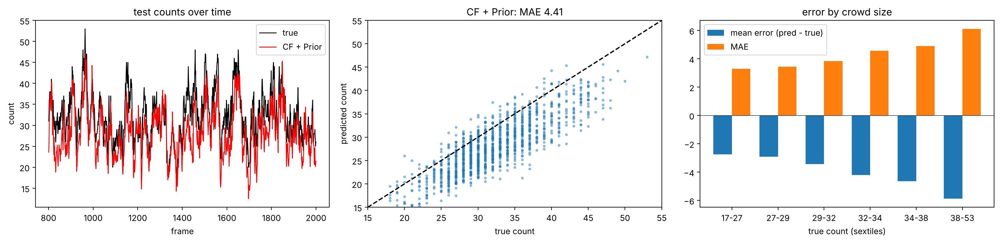

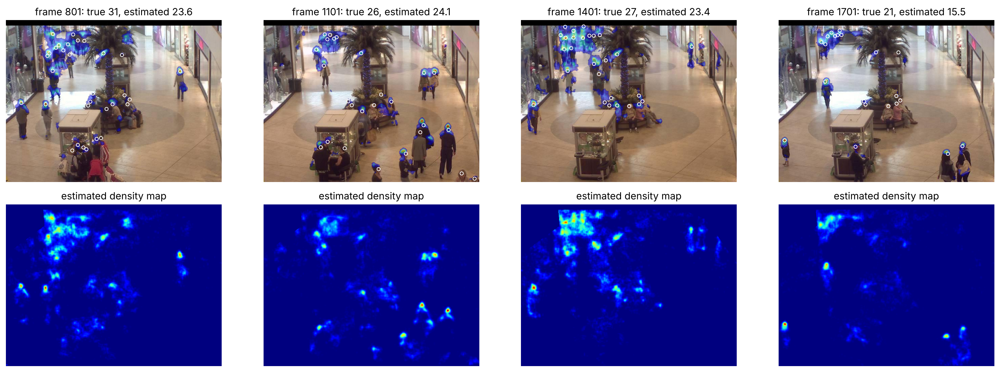

In [22]:
if not TUNING:
    names = [e.name for e in est_test]
    best = min(names, key=lambda n: np.abs(res_test['pred'][n] - res_test['true']).mean())
    ids, tr = res_test['ids'], res_test['true']
    pr = res_test['pred'][best]
    fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
    ax[0].plot(ids + 1, tr, 'k-', lw=1, label='true'); ax[0].plot(ids + 1, pr, 'r-', lw=1, label=best)
    ax[0].set_xlabel('frame'); ax[0].set_ylabel('count'); ax[0].legend(); ax[0].set_title('test counts over time')
    ax[1].scatter(tr, pr, s=6, alpha=.4); lim = [tr.min() - 2, tr.max() + 2]
    ax[1].plot(lim, lim, 'k--'); ax[1].set_xlim(lim); ax[1].set_ylim(lim)
    ax[1].set_xlabel('true count'); ax[1].set_ylabel('predicted count'); ax[1].set_title(f'{best}: MAE {np.abs(pr - tr).mean():.2f}')
    edges = np.percentile(tr, np.linspace(0, 100, 7)); b = np.clip(np.digitize(tr, edges[1:-1]), 0, 5)
    bias = [np.mean(pr[b == k] - tr[b == k]) for k in range(6)]
    mae_b = [np.mean(np.abs(pr[b == k] - tr[b == k])) for k in range(6)]
    lab = [f'{edges[k]:.0f}-{edges[k + 1]:.0f}' for k in range(6)]
    ax[2].bar(np.arange(6) - .2, bias, .4, label='mean error (pred - true)'); ax[2].bar(np.arange(6) + .2, mae_b, .4, label='MAE')
    ax[2].set_xticks(range(6)); ax[2].set_xticklabels(lab); ax[2].axhline(0, c='k', lw=.5)
    ax[2].set_xlabel('true count (sextiles)'); ax[2].legend(); ax[2].set_title('error by crowd size')
    plt.tight_layout(); plt.show()


    show = sorted({int(k.split('|')[1]) for k in res_test['maps']})
    fig, ax = plt.subplots(2, len(show), figsize=(4.4 * len(show), 6.4))
    for c, i in enumerate(show):
        D = res_test['maps'][f'{best}|{i}'] * ROI
        dots = ds['dots'][i]
        ax[0, c].imshow(cv2.cvtColor(read_frame(i), cv2.COLOR_BGR2RGB))
        ax[0, c].imshow(np.ma.masked_less(D, 0.1 * D.max()), cmap='jet', alpha=.5)       # estimated density (top 90% of its range)
        ax[0, c].scatter(dots[:, 0], dots[:, 1], s=16, facecolors='none', edgecolors='w', linewidths=.8)   # true heads
        ax[0, c].set_title(f'frame {i + 1}: true {ds["counts"][i]:.0f}, estimated {D.sum():.1f}')
        ax[1, c].imshow(D, cmap='jet'); ax[1, c].set_title('estimated density map')
        ax[0, c].axis('off'); ax[1, c].axis('off')
    plt.tight_layout(); plt.show()


### 5.5 Results from my run (Mall test set, frames 801–2000, stride 3)

| variant | MAE | MSE | MDE | ms/frame |
|---|---|---|---|---|
| CF | 4.438 | 27.71 | 0.137 | 360 |
| CF + Perm | 4.460 | 27.91 | 0.137 | 195 |
| CF + Prior (N=6) | 4.412 | 27.46 | 0.136 | 367 |
| CF + Prior + Perm | 4.451 | 27.92 | 0.137 | 202 |

The paper reports 2.50 / 10.0 / 0.080 for its full method, so **this reimplementation is not at the paper's level yet**.
- **The error is mostly bias.** All variants undercount by about 13% (mean 28.1 predicted against 32.2 true). The counts follow the truth closely (r = 0.84), and the shortfall grows with crowd size (cell below). On validation the undercount was 7%, so it widened on the test period.
- **Permutation** gives about 1.9× less estimation time at the same accuracy.
- **The prior** has no measurable effect here (4.41 against 4.44).
- **Not yet tested (hypotheses for the undercount):** 300 training patches per frame instead of the paper's 1000; majority-vote leaves, which favour small label sizes; `R_LABEL` tuned on only 40 validation frames; appearance drift between the training and test periods.

In [23]:
if not TUNING:
    ids, tr = res_test['ids'], res_test['true']
    for n in names:
        pr = res_test['pred'][n]
        print(f'{n:20s} mean error {np.mean(pr - tr):6.2f}   MAE {np.mean(np.abs(pr - tr)):.2f}   MAE after removing the mean error {np.mean(np.abs(pr - tr - np.mean(pr - tr))):.2f}   corr {np.corrcoef(tr, pr)[0, 1]:.3f}')
    pr = res_test['pred'][best]
    q = np.percentile(tr, [0, 25, 50, 75, 100])
    print('predicted / true by true-count quartile:', [f'{pr[(tr >= lo) & (tr <= hi)].mean() / tr[(tr >= lo) & (tr <= hi)].mean():.3f}' for lo, hi in zip(q[:-1], q[1:])])
    seg = np.array_split(np.arange(len(tr)), 8)
    print('mean error per eighth of the test period:', [f'{np.mean(pr[s] - tr[s]):.1f}' for s in seg])

CF                   mean error  -4.09   MAE 4.44   MAE after removing the mean error 2.68   corr 0.836
CF + Perm            mean error  -4.12   MAE 4.46   MAE after removing the mean error 2.68   corr 0.837
CF + Prior           mean error  -4.04   MAE 4.41   MAE after removing the mean error 2.69   corr 0.834
CF + Prior + Perm    mean error  -4.08   MAE 4.45   MAE after removing the mean error 2.70   corr 0.833
predicted / true by true-count quartile: ['0.889', '0.885', '0.871', '0.859']
mean error per eighth of the test period: ['-4.9', '-3.4', '-4.4', '-0.8', '-6.0', '-5.2', '-4.5', '-3.1']


# Phase 6: Applications on video (paper Sec. 5.5)
The density maps of the test video give two things beyond a count per frame.
- **Heat map and stationary time.** The paper's second application: *stationary time* is how long a pixel stays occupied, allowing small local movements. Detecting foreground per frame and counting how long a pixel has been foreground works poorly, so the paper estimates a density map per frame and counts how long the density at a pixel stays above a threshold. Seated people (the benches round the palm tree) should show up as long stays, and people walking through as short ones.
- **Demo video.** The test frames with the density overlay, the predicted and true count, and a running count curve.

All of this uses the variant `CF + Perm` (the same accuracy as the plain forest and about 2× cheaper). Its density maps for all 1200 test frames are computed once and cached (about 10 min).

In [24]:
STACK_VARIANT = 'CF + Perm'


def density_stack(frame_ids, estimator, tag):
    """Density maps (inside the ROI, float16) of every frame in frame_ids, computed once and cached as .npy."""
    ids = np.asarray(frame_ids)
    name = estimator.name.replace(' ', '').replace('+', '')
    path = os.path.join(CACHE_DIR, f'dstack_{POOL_TAG}_{tag}_n{len(ids)}_S{EVAL_STRIDE}_{name}.npy')
    if os.path.exists(path):
        print('loaded cached density maps:', path)
        return np.load(path, mmap_mode='r')
    out = np.lib.format.open_memmap(path + '.part', mode='w+', dtype=np.float16, shape=(len(ids), H_IMG, W_IMG))
    estimator.reset()
    where = {int(i): j for j, i in enumerate(ids)}
    t0 = time.time()
    for i, C in stream_channels(int(ids.max())):
        j = where.get(i)
        if j is None:
            continue
        out[j] = (estimator(C) * ROI).astype(np.float16)
        if (j + 1) % 200 == 0:
            print(f'  {j + 1}/{len(ids)} frames, {time.time() - t0:.0f}s')
    out.flush(); del out
    os.replace(path + '.part', path)
    return np.load(path, mmap_mode='r')


if not TUNING:
    stack = density_stack(TEST_FRAMES, next(e for e in est_test if e.name == STACK_VARIANT), 'test')
    n_stack = np.array([float(stack[j].astype(np.float32).sum()) for j in range(len(stack))])
    print(f'{len(stack)} density maps {stack.shape[1:]};  count from the stored maps vs the evaluation run: '
          f'max difference {np.abs(n_stack - res_test["pred"][STACK_VARIANT]).max():.3f}')
else:
    print('Phase 6 runs with TUNING = False (it needs the final forests and the test frames).')

loaded cached density maps: cache/dstack_mall_final_full_p300_s1_R32_pp1_test_n1200_S3_CFPerm.npy


1200 density maps (480, 640);  count from the stored maps vs the evaluation run: max difference 0.000


## 6.1 Heat map and stationary time
**Definition.** A pixel is *occupied* in a frame if the density within `LOCAL_RADIUS` pixels of it is above a threshold. Taking the maximum over a small disk is what allows local movements. A *stay* is a run of consecutive occupied frames. For each pixel the cell computes:
- **occupancy:** the fraction of frames in which it is occupied (a crowd heat map),
- **long-stay time:** the fraction of the video it spends inside stays of at least `MIN_STAY_S` seconds,
- **mean stay:** the average length of its stays, in seconds.

**Check against the ground truth.** The same computation on the annotated heads (a Gaussian per dot, so no model is involved) gives reference maps. I report the correlation between the two sets of maps after a light Gaussian blur.

`TAU_EST` is [ours]: the density of one estimated person peaks around 0.003–0.004 (the Gaussians of overlapping patches average out), so 0.0012 is about a third of that. `TAU_GT` is half the peak of a ground-truth Gaussian.

maps computed in 21s
correlation estimated vs ground truth, mean density (heat map)           : 0.662
correlation estimated vs ground truth, occupancy fraction                : 0.680
correlation estimated vs ground truth, long-stay fraction (>= 10 s)      : 0.580


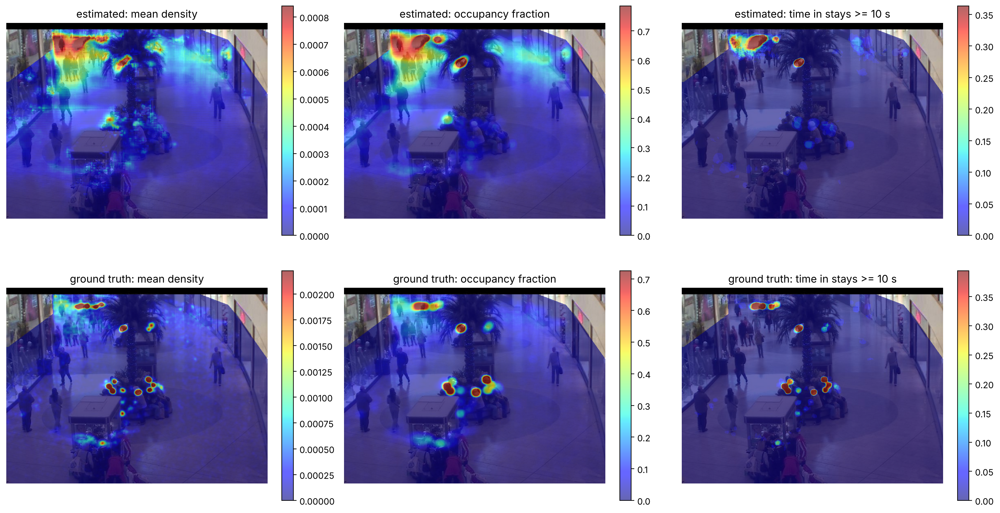

In [25]:
FPS_VIDEO   = 2.0                       # Mall is recorded at 2 frames per second
LOCAL_RADIUS = 8                        # px: a head moving less than this still counts as "stationary"
MIN_STAY_S  = 10                        # a "long stay" lasts at least this many seconds
TAU_EST     = 0.0012                    # [ours] density threshold for the estimated maps
TAU_GT      = 0.5 / (2 * np.pi * SIGMA_GT ** 2)


def stationary_maps(maps, tau, sec_per_frame, radius=LOCAL_RADIUS, min_stay_s=MIN_STAY_S):
    se = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * radius + 1, 2 * radius + 1))
    min_frames = int(np.ceil(min_stay_s / sec_per_frame))
    shp = (H_IMG, W_IMG)
    run, occ_n, stay, ep_sum, ep_n = (np.zeros(shp, np.int32) for _ in range(5))
    T, mean_d = 0, np.zeros(shp, np.float64)
    for D in maps:
        D = np.asarray(D, np.float32)
        occ = cv2.dilate(D, se) > tau                       # some density within `radius` px: the spot is occupied
        ended = (run > 0) & ~occ                            # a stay ends in this frame
        long = ended & (run >= min_frames)
        stay[long] += run[long]; ep_sum[ended] += run[ended]; ep_n[ended] += 1
        run = np.where(occ, run + 1, 0).astype(np.int32)
        occ_n += occ; mean_d += D; T += 1
    ended = run > 0; long = ended & (run >= min_frames)     # stays still going at the end of the video
    stay[long] += run[long]; ep_sum[ended] += run[ended]; ep_n[ended] += 1
    return dict(heat=mean_d / T, occupancy=occ_n / T, long_stay=stay / T,
                mean_stay=np.where(ep_n > 0, ep_sum / np.maximum(ep_n, 1), 0) * sec_per_frame)


def map_corr(a, b, sigma=6):
    a, b = ndi.gaussian_filter(a, sigma)[ROI], ndi.gaussian_filter(b, sigma)[ROI]
    return float(np.corrcoef(a, b)[0, 1])


if not TUNING:
    spf = TEST_STEP / FPS_VIDEO
    t0 = time.time()
    sm_est = stationary_maps((stack[j] for j in range(len(stack))), TAU_EST, spf)
    sm_gt = stationary_maps((gt_density(ds['dots'][i], roi=ROI) for i in TEST_FRAMES), TAU_GT, spf)
    print(f'maps computed in {time.time() - t0:.0f}s')
    for k, label in (('heat', 'mean density (heat map)'), ('occupancy', 'occupancy fraction'), ('long_stay', f'long-stay fraction (>= {MIN_STAY_S} s)')):
        print(f'correlation estimated vs ground truth, {label:34s}: {map_corr(sm_est[k], sm_gt[k]):.3f}')

    bg = cv2.cvtColor(read_frame(int(TEST_FRAMES[0])), cv2.COLOR_BGR2RGB)
    fig, ax = plt.subplots(2, 3, figsize=(16, 8.6))
    for r, (sm, title) in enumerate(((sm_est, 'estimated'), (sm_gt, 'ground truth'))):
        for c, (k, label) in enumerate((('heat', 'mean density'), ('occupancy', 'occupancy fraction'), ('long_stay', f'time in stays >= {MIN_STAY_S} s'))):
            m = np.ma.masked_where(~ROI, sm[k])
            ax[r, c].imshow(bg); im = ax[r, c].imshow(m, cmap='jet', alpha=.6, vmax=np.percentile(sm[k][ROI], 99.5))
            ax[r, c].set_title(f'{title}: {label}'); ax[r, c].axis('off'); plt.colorbar(im, ax=ax[r, c], fraction=.04)
    plt.tight_layout(); plt.show()

**Results from my run.** Correlation between the maps from the estimated density and the maps from the annotated heads: 0.66 (heat map), 0.68 (occupancy), 0.58 (long-stay time).
- The estimated maps find the busy upper-left part of the scene and the seat under the palm tree's upper branches.
- They **miss the benches in the lower middle**, where several people sit close together, partly hidden. The model undercounts such dense, occluded clusters, so those pixels never reach the threshold.
- The top-left blob is wider than in the ground truth, because far-away people give lower, smeared density peaks.

## 6.2 Demo video
Writes `demo_counting.mp4` with the first `VIDEO_FRAMES` test frames at `VIDEO_FPS` frames per second (the original is 2 per second). Each frame shows the density overlay, the predicted and true counts and the count curve so far. In Colab, download it with `from google.colab import files; files.download('demo_counting.mp4')`.

demo_counting.mp4: 300 frames, 5.2 MB


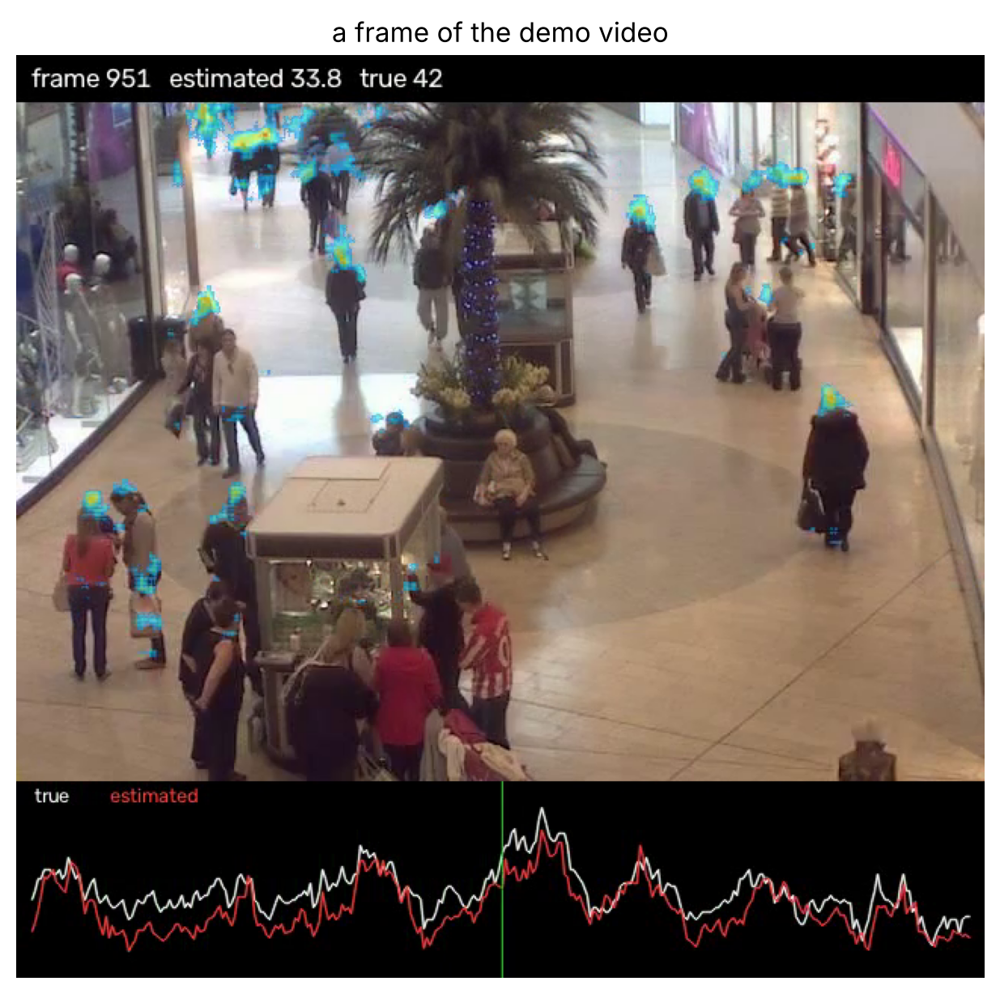

In [26]:
VIDEO_FRAMES, VIDEO_FPS = 300, 8
VIDEO_PATH = 'demo_counting.mp4'


def make_demo_video(path, ids, maps, pred, true, fps=VIDEO_FPS, vmax=0.004):
    import shutil, subprocess
    Wp, Hp, strip = W_IMG, H_IMG, 130
    writer = cv2.VideoWriter(path + '.raw.mp4', cv2.VideoWriter_fourcc(*'mp4v'), fps, (Wp, Hp + strip))
    n = len(ids)
    lo, hi = min(pred.min(), true.min()) - 2, max(pred.max(), true.max()) + 2
    px = lambda k: int(10 + (Wp - 20) * k / max(n - 1, 1))
    py = lambda v: int(strip - 12 - (strip - 24) * (v - lo) / (hi - lo))
    base = np.zeros((strip, Wp, 3), np.uint8)
    cv2.polylines(base, [np.array([[px(k), py(v)] for k, v in enumerate(true)], np.int32)], False, (255, 255, 255), 1, cv2.LINE_AA)
    cv2.polylines(base, [np.array([[px(k), py(v)] for k, v in enumerate(pred)], np.int32)], False, (60, 60, 255), 1, cv2.LINE_AA)
    cv2.putText(base, 'true', (12, 14), cv2.FONT_HERSHEY_SIMPLEX, .45, (255, 255, 255), 1, cv2.LINE_AA)
    cv2.putText(base, 'estimated', (62, 14), cv2.FONT_HERSHEY_SIMPLEX, .45, (60, 60, 255), 1, cv2.LINE_AA)
    for j in range(n):
        img = read_frame(int(ids[j]))
        a = np.clip(np.asarray(maps[j], np.float32) / vmax, 0, 1)
        heat = cv2.applyColorMap((a * 255).astype(np.uint8), cv2.COLORMAP_JET)
        w = (0.6 * (a > 0.25))[..., None]
        out = (img * (1 - w) + heat * w).astype(np.uint8)
        cv2.rectangle(out, (0, 0), (Wp, 30), (0, 0, 0), -1)
        cv2.putText(out, f'frame {int(ids[j]) + 1}   estimated {pred[j]:.1f}   true {true[j]:.0f}', (10, 21),
                    cv2.FONT_HERSHEY_SIMPLEX, .6, (255, 255, 255), 1, cv2.LINE_AA)
        panel = base.copy(); cv2.line(panel, (px(j), 0), (px(j), strip), (0, 220, 0), 1)
        writer.write(np.vstack([out, panel]))
    writer.release()
    if shutil.which('ffmpeg'):                      # re-encode to H.264 so that browsers and phones can play it
        subprocess.run(['ffmpeg', '-y', '-loglevel', 'error', '-i', path + '.raw.mp4', '-c:v', 'libx264',
                        '-pix_fmt', 'yuv420p', '-crf', '23', path], check=True)
        os.remove(path + '.raw.mp4')
    else:
        os.replace(path + '.raw.mp4', path)
    return path


if not TUNING:
    nv = min(VIDEO_FRAMES, len(stack))
    vp = make_demo_video(VIDEO_PATH, TEST_FRAMES[:nv], stack, n_stack[:nv], ds['counts'][TEST_FRAMES[:nv]])
    cap = cv2.VideoCapture(vp); cap.set(cv2.CAP_PROP_POS_FRAMES, nv // 2); ok, fr = cap.read(); cap.release()
    print(f'{vp}: {nv} frames, {os.path.getsize(vp) / 1e6:.1f} MB')
    plt.figure(figsize=(8, 7.4)); plt.imshow(cv2.cvtColor(fr, cv2.COLOR_BGR2RGB)); plt.axis('off'); plt.title('a frame of the demo video'); plt.show()

# Phase 8: Ablations on Mall (validation frames 701–800)
Every ablation trains on frames 1–700 and is scored on frames 701–800 with the plain-forest estimator at stride 3. The test frames are not used here. Differences of about 0.1 MAE or less are within what 100 correlated frames and one random seed can resolve; 8.1 measures that noise directly by retraining with another seed.

This section uses its own tuning-split pools, so it works whatever `TUNING` is set to (it builds them once if they are missing). Each result is cached as JSON in `cache/ablate_*.json`.

| ablation | what changes | needs retraining |
|---|---|---|
| 8.1 number of trees, patch stride, seed | use fewer trees, a coarser patch grid, another seed | no (seed: yes) |
| 8.2 split layers, feature groups | one split layer only; drop channel groups | yes |
| 8.3 label radius R | R = 12, 18, 24, 40 (the pool is relabelled, the features are reused) | yes |
| 8.4 perspective weighting, training-set size | features × pmap² instead of pmap; 100 instead of 300 patches per frame | yes |

In [27]:
TUNE_TAG = f'{DATASET}_tune_{"dev" if FAST_DEV else "full"}_p{PATCHES_PER_FRAME}_s{FRAME_STEP}_R{R_LABEL:g}_pp{PERSP_POWER:g}'
TUNE_TRAIN_DIR, TUNE_VAL_DIR = (os.path.join(CACHE_DIR, f'pool_{g}_{TUNE_TAG}') for g in ('train', 'val'))
ABL_TRAIN, ABL_VAL = np.arange(700)[::FRAME_STEP], np.arange(700, 800)

_need = {}
if not os.path.exists(os.path.join(TUNE_TRAIN_DIR, 'meta.npy')):
    _need['train'] = ABL_TRAIN
if not os.path.exists(os.path.join(TUNE_VAL_DIR, 'meta.npy')):
    _need['val'] = ABL_VAL[::FRAME_STEP]
if _need:
    _pools = build_patch_pools(_need, PATCHES_PER_FRAME, SEED)
    for g, P in _pools.items():
        save_pool(P, TUNE_TRAIN_DIR if g == 'train' else TUNE_VAL_DIR)
    del _pools

TUNE_FOREST_PATH = os.path.join(CACHE_DIR, f'forest_{TUNE_TAG}_T{N_TREES}.joblib')
if os.path.exists(TUNE_FOREST_PATH):
    tune_forest = joblib.load(TUNE_FOREST_PATH)
else:
    tune_forest = train_forest(TUNE_TRAIN_DIR); joblib.dump(tune_forest, TUNE_FOREST_PATH)

# the 100 validation frames' channels, computed once (float16, ~0.9 GB on disk)
VC_PATH = os.path.join(CACHE_DIR, f'valC16_{TUNE_TAG}.npy')
if not os.path.exists(VC_PATH):
    _vc = np.lib.format.open_memmap(VC_PATH + '.part', mode='w+', dtype=np.float16, shape=(len(ABL_VAL), N_CH, H_IMG, W_IMG))
    for i, C in stream_channels(int(ABL_VAL.max())):
        if i >= ABL_VAL.min():
            _vc[i - ABL_VAL.min()] = C.astype(np.float16)
    _vc.flush(); del _vc; os.replace(VC_PATH + '.part', VC_PATH)
VC = np.load(VC_PATH, mmap_mode='r')
_GRIDS = {}


def abl_eval(trees, stride=EVAL_STRIDE, n_sub=1, weight=None):
    """Plain-forest counts on the 100 validation frames. weight: extra per-pixel factor applied to the channels."""
    g = _GRIDS.setdefault(stride, make_grid(stride))
    fast = [prepare_tree(dict(t)) for t in trees]
    groups = patch_groups(g, [fast], None, 4) if n_sub == 4 else [(fast, None)]
    pred, sec = np.zeros(len(ABL_VAL)), 0.0
    for j in range(len(ABL_VAL)):
        C = np.asarray(VC[j])
        if weight is not None:
            C = (C.astype(np.float32) * weight[None]).astype(np.float16)
        t0 = time.time(); D = density_fast(C, g, groups); sec += time.time() - t0
        pred[j] = float((D * ROI).sum())
    m = count_metrics(ds['counts'][ABL_VAL], pred)
    return dict(MAE=float(m['MAE']), MSE=float(m['MSE']), MDE=float(m['MDE']), mean_pred=float(pred.mean()), ms=sec / len(ABL_VAL) * 1000)


def cached(name, fn):
    p = os.path.join(CACHE_DIR, f'ablate_{TUNE_TAG}_{name}.json')
    if os.path.exists(p):
        return json.load(open(p))
    r = fn(); json.dump(r, open(p, 'w')); return r


def show(title, rows, ms=False):
    print(title)
    for label, r in rows.items():
        print(f'  {label:44s} MAE {r["MAE"]:.3f}   MSE {r["MSE"]:6.2f}   MDE {r["MDE"]:.3f}   mean count {r["mean_pred"]:5.2f}' + (f'   {r["ms"]:5.0f} ms/frame' if ms else ''))


# regression check: the training code was extended with options (split layers, feature subsets); with the defaults it must reproduce the cached forest
_t0 = _train_one(0, TUNE_TRAIN_DIR, None, SAMPLES_PER_TREE, SEED)
assert all(np.array_equal(_t0[k], tune_forest[0][k]) for k in ('feature', 'threshold', 'left', 'right', 'leaf_k', 'points')), 'training changed'
print('training code with default options reproduces the cached forest (tree 0 identical)')
ABL = {}
ABL['base'] = cached('base', lambda: abl_eval(tune_forest))
show('base forest (32 trees, 2 split layers, R=%g, stride %d)' % (R_LABEL, EVAL_STRIDE), {'base': ABL['base']}, ms=True)

training code with default options reproduces the cached forest (tree 0 identical)


base forest (32 trees, 2 split layers, R=32, stride 3)
  base                                         MAE 3.124   MSE  13.55   MDE 0.089   mean count 33.23     314 ms/frame


## 8.1 Number of trees, patch stride, random seed
- **Trees.** The trees are independent, so the first T trees of the forest are a T-tree forest.
- **Stride.** A larger stride samples fewer patches per frame (a patch every `stride` pixels), which is faster. With forest permutation, each patch also uses only a quarter of the trees.
- **Seed.** The whole forest is retrained with another random seed (a different bag and different random split candidates per tree). The difference from the base forest is the noise level of every comparison in this section.

In [28]:
ABL['trees'] = {str(T): cached(f'trees{T}', lambda T=T: abl_eval(tune_forest[:T])) for T in (1, 2, 4, 8, 16, 32)}
show('number of trees', {f'{T} trees': r for T, r in ABL['trees'].items()}, ms=True)

ABL['stride'] = {}
for s in (2, 3, 4, 6, 8):
    ABL['stride'][str(s)] = dict(plain=cached(f'stride{s}', lambda s=s: abl_eval(tune_forest, stride=s)),
                                 perm=cached(f'stride{s}_perm', lambda s=s: abl_eval(tune_forest, stride=s, n_sub=4)))
show('patch stride, all 32 trees per patch', {f'stride {s}': r['plain'] for s, r in ABL['stride'].items()}, ms=True)
show('patch stride, forest permutation (8 trees per patch)', {f'stride {s}': r['perm'] for s, r in ABL['stride'].items()}, ms=True)

ABL['seed1'] = cached('seed1', lambda: abl_eval(train_forest(TUNE_TRAIN_DIR, seed=SEED + 1)))
show('another random seed', {'seed 0 (base)': ABL['base'], 'seed 1': ABL['seed1']})
print(f'noise level: |MAE(seed 1) - MAE(seed 0)| = {abs(ABL["seed1"]["MAE"] - ABL["base"]["MAE"]):.3f}')

number of trees
  1 trees                                      MAE 3.768   MSE  21.52   MDE 0.107   mean count 32.89      54 ms/frame
  2 trees                                      MAE 2.461   MSE  10.01   MDE 0.069   mean count 35.91      60 ms/frame
  4 trees                                      MAE 2.398   MSE   9.02   MDE 0.068   mean count 35.34      77 ms/frame
  8 trees                                      MAE 2.374   MSE   8.52   MDE 0.069   mean count 34.84     117 ms/frame
  16 trees                                     MAE 2.210   MSE   7.53   MDE 0.064   mean count 35.31     175 ms/frame
  32 trees                                     MAE 3.124   MSE  13.55   MDE 0.089   mean count 33.23     316 ms/frame


patch stride, all 32 trees per patch
  stride 2                                     MAE 3.080   MSE  13.19   MDE 0.088   mean count 33.30     733 ms/frame
  stride 3                                     MAE 3.124   MSE  13.55   MDE 0.089   mean count 33.23     302 ms/frame
  stride 4                                     MAE 3.049   MSE  12.90   MDE 0.087   mean count 33.35     175 ms/frame
  stride 6                                     MAE 3.137   MSE  13.54   MDE 0.090   mean count 33.21      85 ms/frame
  stride 8                                     MAE 3.411   MSE  15.76   MDE 0.097   mean count 32.87      51 ms/frame
patch stride, forest permutation (8 trees per patch)
  stride 2                                     MAE 3.072   MSE  13.14   MDE 0.088   mean count 33.30     285 ms/frame
  stride 3                                     MAE 3.100   MSE  13.36   MDE 0.088   mean count 33.24     118 ms/frame
  stride 4                                     MAE 3.005   MSE  12.59   MDE 0.086   

trained 32 trees in 141s


another random seed
  seed 0 (base)                                MAE 3.124   MSE  13.55   MDE 0.089   mean count 33.23
  seed 1                                       MAE 3.367   MSE  15.78   MDE 0.096   mean count 32.92
noise level: |MAE(seed 1) - MAE(seed 0)| = 0.243


## 8.2 Split layers and feature groups
- **Split layers.** The paper's forest has two split layers. Here each is used alone: *lower only* splits every node by the entropy of the label sizes K, *upper throughout* splits by the variance of the head-position histograms until nodes have fewer than 40 samples.
- **Feature groups.** Split candidates are drawn only from the allowed channels; everything else is unchanged. *No temporal channels* removes the background-subtraction mask and the temporal difference, so the forest sees a single still image. *No structure tensor* removes the 6 eigenvalue channels. *Finest scale only* keeps gray, the two temporal channels and the four scale-0.8 channels.

In [29]:
ABL['layers'] = {'two layers (paper)': ABL['base']}
ABL['layers']['lower layer only (label-size entropy)'] = cached('layer_lower', lambda: abl_eval(train_forest(TUNE_TRAIN_DIR, upper_depth=0)))
ABL['layers']['upper layer throughout (position variance)'] = cached('layer_upper', lambda: abl_eval(train_forest(TUNE_TRAIN_DIR, upper_depth=MAX_DEPTH)))
show('split layers', ABL['layers'])

def chan_features(chs):
    return np.concatenate([np.arange(c * PATCH * PATCH, (c + 1) * PATCH * PATCH) for c in chs])

FEATURE_GROUPS = {
    'no temporal channels (bgsub, dI/dt)': [i for i, n in enumerate(CHANNEL_NAMES) if n not in ('bgsub', 'dI/dt')],
    'no structure-tensor channels':        [i for i, n in enumerate(CHANNEL_NAMES) if not n.startswith('st_')],
    'finest scale only (0.8)':             [i for i, n in enumerate(CHANNEL_NAMES) if '@' not in n or n.endswith('@0.8')],
}
ABL['features'] = {'all 15 channels (paper)': ABL['base']}
for k, (name, chs) in enumerate(FEATURE_GROUPS.items()):
    ABL['features'][f'{name}: {len(chs)} channels'] = cached(f'feat{k}', lambda chs=chs: abl_eval(train_forest(TUNE_TRAIN_DIR, allowed=chan_features(chs))))
show('feature groups', ABL['features'])

trained 32 trees in 108s


trained 32 trees in 105s


split layers
  two layers (paper)                           MAE 3.124   MSE  13.55   MDE 0.089   mean count 33.23
  lower layer only (label-size entropy)        MAE 2.866   MSE  13.15   MDE 0.079   mean count 37.41
  upper layer throughout (position variance)   MAE 8.312   MSE  75.85   MDE 0.236   mean count 27.49


trained 32 trees in 102s


trained 32 trees in 81s


trained 32 trees in 86s


feature groups
  all 15 channels (paper)                      MAE 3.124   MSE  13.55   MDE 0.089   mean count 33.23
  no temporal channels (bgsub, dI/dt): 13 channels MAE 6.325   MSE  54.44   MDE 0.165   mean count 29.51
  no structure-tensor channels: 9 channels     MAE 8.668   MSE  82.91   MDE 0.245   mean count 27.13
  finest scale only (0.8): 7 channels          MAE 5.342   MSE  35.09   MDE 0.153   mean count 30.58


## 8.3 Label radius R
The paper does not give R, the radius within which heads belong to a patch's label. The pool is relabelled for each R (the patch features do not depend on it; only `Dpad`, `K` and `H` change) and a forest is trained on it.

In [30]:
def soft_hist_R(Dpad, R):
    e = np.linspace(-R, R, HIST_BINS + 1); c = (e[:-1] + e[1:]) / 2; cx, cy = np.meshgrid(c, c); s = e[1] - e[0]
    out = np.empty((len(Dpad), HIST_BINS * HIST_BINS), np.float32)
    for a in range(0, len(Dpad), 10000):
        d = Dpad[a:a + 10000]
        w = np.exp(-((d[:, :, 0][:, :, None] - cx.ravel()) ** 2 + (d[:, :, 1][:, :, None] - cy.ravel()) ** 2) / (2 * s ** 2))
        out[a:a + 10000] = np.nan_to_num(w).sum(1)
    return out


def _link_or_copy(src, dst):
    """Reuse the big feature file V.npy without copying it where possible. A symlink needs admin rights or Developer Mode on
    Windows, so fall back to a hard link, and finally to a plain copy."""
    import shutil
    if os.path.lexists(dst):
        os.remove(dst)
    try:
        os.symlink(src, dst)
    except (OSError, NotImplementedError):
        try:
            os.link(src, dst)
        except (OSError, NotImplementedError):
            shutil.copyfile(src, dst)


def relabel_pool(src, R):
    dst = f'{src}_R{R:g}'
    if all(os.path.exists(os.path.join(dst, f)) for f in ('meta.npy', 'V.npy')):   # complete only if the features are there too
        return dst
    os.makedirs(dst, exist_ok=True)
    meta = np.load(os.path.join(src, 'meta.npy'))
    Dpad, K = np.empty((len(meta), K_MAX, 2), np.float32), np.empty(len(meta), np.int16)
    for f in np.unique(meta[:, 0]):
        sel = np.nonzero(meta[:, 0] == f)[0]
        Dpad[sel], K[sel] = make_labels(meta[sel, 1:], ds['dots'][f], R=R)
    for k, v in dict(Dpad=Dpad, K=K, H=soft_hist_R(Dpad, R), meta=meta).items():
        np.save(os.path.join(dst, k + '.npy'), v)
    _link_or_copy(os.path.abspath(os.path.join(src, 'V.npy')), os.path.join(dst, 'V.npy'))   # same features: link if possible, else copy
    return dst


ABL['R'] = {}
for R in (12, 18, 24, 32, 40):
    if R == R_LABEL:
        ABL['R'][str(R)] = ABL['base']
    else:
        ABL['R'][str(R)] = cached(f'R{R}', lambda R=R: abl_eval(train_forest(relabel_pool(TUNE_TRAIN_DIR, R))))
show('label radius R (pixels)', {f'R = {R}': r for R, r in ABL['R'].items()})

trained 32 trees in 90s


trained 32 trees in 92s


trained 32 trees in 103s


trained 32 trees in 105s


label radius R (pixels)
  R = 12                                       MAE 9.164   MSE  96.37   MDE 0.257   mean count 26.64
  R = 18                                       MAE 3.926   MSE  24.12   MDE 0.113   mean count 38.65
  R = 24                                       MAE 2.837   MSE  12.73   MDE 0.084   mean count 36.48
  R = 32                                       MAE 3.124   MSE  13.55   MDE 0.089   mean count 33.23
  R = 40                                       MAE 4.239   MSE  25.44   MDE 0.115   mean count 31.73


## 8.4 Perspective weighting and training-set size
- **Perspective weighting.** The paper multiplies the features by the square of the perspective map. The default here is the map itself (`PERSP_POWER = 1`), because Mall's map is already an area scale. The pool is re-weighted exactly (each pixel of each stored patch × another factor of the map at that pixel) and the validation channels likewise.
- **Training-set size.** The paper takes 1000 patches per frame; this implementation uses 300 to fit in memory. Here a forest is trained on the first 100 of each frame's 300 patches. (1000 per frame was not run.)

In [31]:
def reweight_pool(src, extra_power):
    dst = f'{src}_x{extra_power:g}'
    if os.path.exists(os.path.join(dst, 'meta.npy')):
        return dst
    os.makedirs(dst, exist_ok=True)
    P = load_pool(src)
    meta, w = np.asarray(P['meta']), ds['pmap'].astype(np.float32) ** extra_power
    V2 = np.lib.format.open_memmap(os.path.join(dst, 'V.npy'), mode='w+', dtype=np.float16, shape=P['V'].shape)
    for a in range(0, len(meta), 10000):
        m = meta[a:a + 10000]
        wp = w[m[:, 2:3] + OFF_Y[None], m[:, 1:2] + OFF_X[None]]                      # weight of every pixel of every patch
        V2[a:a + 10000] = (np.asarray(P['V'][a:a + 10000], np.float32).reshape(len(m), N_CH, -1) * wp[:, None, :]).reshape(len(m), -1).astype(np.float16)
    V2.flush(); del V2
    for k in ('Dpad', 'K', 'H', 'meta'):
        np.save(os.path.join(dst, k + '.npy'), np.asarray(P[k]))
    return dst


ABL['persp'] = {f'pmap^{PERSP_POWER:g} (default)': ABL['base']}
ABL['persp'][f'pmap^{PERSP_POWER + 1:g} (the paper)'] = cached('pp2', lambda: abl_eval(
    train_forest(reweight_pool(TUNE_TRAIN_DIR, 1.0)), weight=ds['pmap'].astype(np.float32) ** 1.0))
show('perspective weighting', ABL['persp'])

ABL['patches'] = {'300 patches per frame (default)': ABL['base']}
if PATCHES_PER_FRAME >= 300:
    _K = np.load(os.path.join(TUNE_TRAIN_DIR, 'K.npy'))
    _sub = np.nonzero(np.arange(len(_K)) % PATCHES_PER_FRAME < 100)[0]
    ABL['patches']['100 patches per frame'] = cached('patches100', lambda: abl_eval(train_forest(TUNE_TRAIN_DIR, subset=_sub)))
show('training-set size', ABL['patches'])

trained 32 trees in 98s


perspective weighting
  pmap^1 (default)                             MAE 3.124   MSE  13.55   MDE 0.089   mean count 33.23
  pmap^2 (the paper)                           MAE 2.916   MSE  13.23   MDE 0.083   mean count 37.60


trained 32 trees in 67s


training-set size
  300 patches per frame (default)              MAE 3.124   MSE  13.55   MDE 0.089   mean count 33.23
  100 patches per frame                        MAE 2.680   MSE  10.58   MDE 0.076   mean count 34.04


## 8.5 Summary
The first panels show how the validation MAE moves with the number of trees, the patch stride and R. The last panel lists the retraining ablations as bars; the shaded band is the seed-to-seed difference measured in 8.1, so a bar inside it is not a real change.

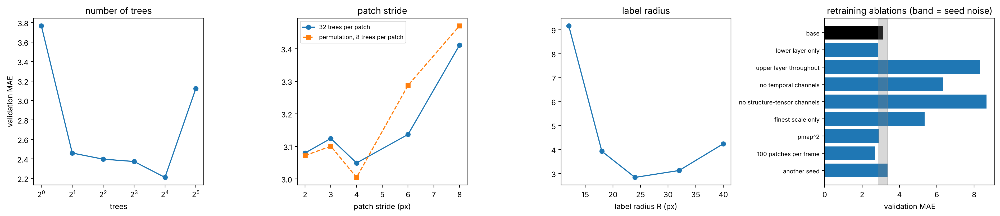

In [32]:
fig, ax = plt.subplots(1, 4, figsize=(19, 4.2))
T = list(ABL['trees']); ax[0].plot([int(t) for t in T], [ABL['trees'][t]['MAE'] for t in T], 'o-'); ax[0].set_xscale('log', base=2)
ax[0].set_xlabel('trees'); ax[0].set_ylabel('validation MAE'); ax[0].set_title('number of trees')
S = list(ABL['stride']); ax[1].plot([int(s) for s in S], [ABL['stride'][s]['plain']['MAE'] for s in S], 'o-', label='32 trees per patch')
ax[1].plot([int(s) for s in S], [ABL['stride'][s]['perm']['MAE'] for s in S], 's--', label='permutation, 8 trees per patch')
ax[1].set_xlabel('patch stride (px)'); ax[1].set_title('patch stride'); ax[1].legend(fontsize=8)
Rs = list(ABL['R']); ax[2].plot([int(r) for r in Rs], [ABL['R'][r]['MAE'] for r in Rs], 'o-'); ax[2].set_xlabel('label radius R (px)'); ax[2].set_title('label radius')
rows = {'base': ABL['base']}
rows.update({k.split(' (')[0].split(':')[0]: v for k, v in list(ABL['layers'].items())[1:] + list(ABL['features'].items())[1:] + list(ABL['persp'].items())[1:] + list(ABL['patches'].items())[1:]})
rows['another seed'] = ABL['seed1']
names = list(rows); vals = [rows[n]['MAE'] for n in names]
ax[3].barh(range(len(names)), vals, color=['k'] + ['C0'] * (len(names) - 1)); ax[3].set_yticks(range(len(names))); ax[3].set_yticklabels(names, fontsize=8)
noise = abs(ABL['seed1']['MAE'] - ABL['base']['MAE'])
ax[3].axvspan(ABL['base']['MAE'] - noise, ABL['base']['MAE'] + noise, color='gray', alpha=.3); ax[3].invert_yaxis()
ax[3].set_xlabel('validation MAE'); ax[3].set_title('retraining ablations (band = seed noise)')
plt.tight_layout(); plt.show()
json.dump(ABL, open(os.path.join(CACHE_DIR, f'ablations_{TUNE_TAG}.json'), 'w'), indent=1)

## What's saved, and what comes next
- `cache/pool_*`: training patches. `cache/forest_*.joblib`: the plain forest and the crowded / non-crowded forests, as flat arrays.
- `cache/eval_*.npz`: per-frame counts of every variant (validation and test), plus a few density maps.
- `cache/dstack_*.npy`: the density maps of all test frames (Phase 6). `demo_counting.mp4`: the demo video.
- `cache/ablations_*.json`: every number of Phase 8.

**Not done**
- **Phase 7 (optional):** semi-automatic training with GrabCut person masks pasted onto the background (Sec. 4.3). It needs the PETS2009 images with their bounding boxes.
- **UCSD:** the loader is untested and `R_LABEL` would need re-tuning for its smaller people.
- **1000 patches per frame**, the paper's setting, and ablations of the patch size and of the depth limits.